<a href="https://colab.research.google.com/github/duartegonzaloariel/UDELAR_Astrometric-calibration-/blob/main/sky_coordinates_prediction4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SKY COORDINATES PREDICTION

# 0. Initialization

## 0.1. Libraries

In [71]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
#from torchinfo import summary
from torch.nn import TransformerEncoder, TransformerEncoderLayer

from sklearn.metrics import mean_squared_error

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import scipy.stats as stats

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

from google.colab import drive

## 0.2. PLATFORM

In [72]:
VERBOSE = True
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
cuda_available = torch.cuda.is_available()
print(f"CUDA Available:  {cuda_available}")

if cuda_available:
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    print(f"GPU Device:\t {torch.cuda.get_device_name(0)}")
    mem_free, mem_total = torch.cuda.mem_get_info(device)
    # Convertir a MB
    mem_free_MB = mem_free / (1024 ** 3)
    mem_total_MB = mem_total / (1024 ** 3)
    print(f"Memoria libre: \t {mem_free_MB:.2f} GB")
    print(f"Memoria total: \t {mem_total_MB:.2f} GB")
    print(f"Memoria usada: \t {mem_total_MB - mem_free_MB:.2f} GB")
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')

print('Selected device:',device)

CUDA Available:  False
Selected device: cpu


## 0.3. Drive

In [73]:
# Monta tu unidad de Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. DATOS

In [74]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

**CONFIGURACION**

---



In [75]:
# =========================
# CONFIG
# =========================
RANDOM_SEED = 40

SPLIT_TRAIN_TEST = 0.2   # fracción para test
BATCH  = 32
EPOCHS = 1000
LOOPS  = 5

# Coordenadas del centro
X0 = 1548 // 2
Y0 = 1040 // 2

# ESTACION: numero de estacion (int) para single-station (filtra df_global
# por esa estacion despues de cargarlo) | 'global' para multi-station (usa
# todas las estaciones de df_global sin filtrar).
# --- antes: nombre = 'df_global'  # 'df_17' para single-station | 'df_global' para multi-station ---
ESTACION = '20'   # ejemplo single-station: ESTACION = 17

DATA_NORMALIZATION   = True
DATA_AUGMENTATION    = False
# --- antes: DATA_FILTER_OUTLIERS = True (manual, había que acordarse de
# cambiarlo a mano segun ESTACION) ---
DATA_FILTER_OUTLIERS = (str(ESTACION).strip().lower() == 'global')  # True solo si ESTACION='global' (multi-station); False en single-station
# --- antes: False ---

# =========================
# FINE-TUNING (NUEVO)
# =========================
# FINE_TUNING: solo tiene efecto cuando ESTACION es una estación individual
# (no 'global'). Requiere haber corrido antes, en el mismo runtime, una
# pasada con ESTACION='global' (deja guardados en memoria el scaler y el
# ajuste clasico de esa corrida global, que se reusan aca en vez de
# recalcularlos con los datos de la estacion sola). Si es False, el
# pipeline se comporta exactamente igual que hasta ahora (scaler y ajuste
# clasico propios de la estacion) y los bloques de fine-tuning no corren.
FINE_TUNING = False

# =========================
# AJUSTE CLASICO (previo, opcional)
# =========================
# Estos dos flags son jerárquicos, no independientes: AJUSTE_CLASICO decide
# si se hace o no el ajuste; AJUSTE_CLASICO_POR_ESTACION solo importa si el
# primero está en True (si AJUSTE_CLASICO=False, el segundo se ignora).
#
# AJUSTE_CLASICO:
#   True  -> antes de entrenar la red, se ajusta un modelo geometrico clasico
#            (distorsion radial respecto al centro optico + orientacion)
#            sobre los datos CRUDOS (sin normalizar), usando SOLO train_df
#            para no filtrar informacion del test. La red pasa entonces a
#            aprender el RESIDUO (real - clasico) en vez del valor real de
#            azimuth/zenith.
#   False -> el pipeline se comporta EXACTAMENTE igual que antes, sin ningun
#            ajuste previo (nada cambia respecto a lo que ya veniamos haciendo).
#
# AJUSTE_CLASICO_POR_ESTACION (solo aplica si AJUSTE_CLASICO=True):
#   True  -> el ajuste clasico (zenith=f(r) + offset de azimuth) se calcula
#            POR ESTACION (cada cámara puede tener su propia distorsión
#            óptica y su propia orientación de montaje).
#   False -> se calcula un unico ajuste GLOBAL con todo TRAIN, mezclando
#            todas las estaciones (comportamiento anterior a este cambio).
#
# Las 4 combinaciones posibles:
#   AJUSTE_CLASICO=True  + POR_ESTACION=True  -> residuo, ajuste por cámara
#                                                 (recomendado en multi-estación).
#   AJUSTE_CLASICO=True  + POR_ESTACION=False -> residuo, ajuste global unico
#                                                 (comportamiento previo a este cambio).
#   AJUSTE_CLASICO=False + POR_ESTACION=True  -> sin efecto: el flag de
#                                                 estacion no se usa, la red
#                                                 aprende azimuth/zenith directo.
#   AJUSTE_CLASICO=False + POR_ESTACION=False -> sin ajuste clasico, red
#                                                 aprende azimuth/zenith directo
#                                                 (comportamiento original del notebook).
AJUSTE_CLASICO = True
AJUSTE_CLASICO_GRADO = 3  # grado del polinomio radial usado en el ajuste clasico (zenith = f(r))
AJUSTE_CLASICO_POR_ESTACION = True


# Modelo
model_name = 'CNN'  # 'DENSE', 'DENSE_BAYESIAN', 'CNN'

# =========================
# LOSS
# =========================
# NUEVO: 'criterion' YA NO se crea acá. Los targets tienen escalas muy
# distintas (zenith en grados vs azimuth_sin/cos adimensional, y mas aun
# siendo residuos), y una MSELoss simple sin ponderar queda dominada por la
# componente de mayor varianza. LOSS_PONDERADA_POR_TAREA controla si se usa
# una MSE ponderada por 1/varianza de cada componente (calculada con TRAIN)
# en vez de una MSE simple. El objeto 'criterion' final se arma mas adelante,
# en la celda de preparacion de datos (2.), una vez que existen train_df y
# COLUMNS_TARGET (necesarios para calcular las varianzas).
LOSS_PONDERADA_POR_TAREA = True  # True: pondera cada salida por 1/varianza | False: MSELoss simple sin ponderar (comportamiento original)

class WeightedMSELoss(nn.Module):
    """MSE ponderada por componente de salida (ver LOSS_PONDERADA_POR_TAREA)."""
    def __init__(self, weights):
        super().__init__()
        self.register_buffer('weights', torch.as_tensor(weights, dtype=torch.float32))

    def forward(self, outputs, targets):
        se = (outputs - targets) ** 2
        return (se * self.weights.to(outputs.device)).mean()

# =========================
# TARGET TASK
# =========================
TASK = "A"  # "A": (X,Y) -> (azimuth, zenith) | "B": (azimuth, zenith) -> (X,Y)

# one-hot de station
STATION_ONEHOT_COLS = [
    'station_1','station_2','station_3','station_4','station_5','station_6','station_7','station_8',
    'station_9','station_10','station_12','station_13','station_14','station_15','station_16','station_17',
    'station_19','station_20'
]

np.random.seed(RANDOM_SEED)

## 1.1. Carga y Preparación de los Datos

### 1.1.1. Load CSV in Dataframes

In [76]:
# Configuración de ruta y tipo de archivo
PATH_BASE  = "/content/drive/MyDrive/InvestigacionesPropias/Fireball/estrellas/calibracion/"

tipo_tabla = "csv"  # "csv" o "excel", según el formato de los archivos en PATH_BASE

# NOMBRE_ARCHIVO_BASE: prefijo fijo del archivo a cargar. Ya no depende de
# la estacion (esa distincion la maneja ESTACION, filtrando data_df despues
# de cargar) -- siempre se carga df_global.
NOMBRE_ARCHIVO_BASE = "df_global"

El código une varios archivos (CSV o Excel) con datos de coordenadas, les agrega un identificador y calcula para cada punto su distancia y ángulo respecto al centro (774, 520), mostrando luego un resumen del DataFrame final.

In [77]:
# Manejo de archivos CSV
if tipo_tabla == "csv":
    # --- antes: f.startswith(nombre) -- ahora siempre se carga el/los
    # archivo(s) de df_global; el filtro por estacion se aplica despues,
    # sobre data_df, usando ESTACION ---
    csv_files = [f for f in os.listdir(PATH_BASE) if f.endswith('.csv') and f.startswith(NOMBRE_ARCHIVO_BASE)]

    df_list = []
    print('CSV FILE LIST\n---------------')
    for ix, file in enumerate(csv_files):
        file_path = os.path.join(PATH_BASE, file)
        df_file = pd.read_csv(file_path)
        df_file['csv'] = (np.ones(len(df_file)) * ix).astype(int)
        print(file_path, '\tN Samples: ', len(df_file))

        df_list.append(df_file)

    data_df = pd.concat(df_list, ignore_index=True)

# Manejo de archivos Excel
elif tipo_tabla == "excel":
    excel_files = [f for f in os.listdir(PATH_BASE) if f.endswith('.xlsx') or f.endswith('.xls')]

    df_list = []
    print('EXCEL FILE LIST\n---------------')
    for ix, file in enumerate(excel_files):
        file_path = os.path.join(PATH_BASE, file)
        df_file = pd.read_excel(file_path)
        df_file['excel'] = (np.ones(len(df_file)) * ix).astype(int)
        print(file_path, '\tN Samples: ', len(df_file))

        df_list.append(df_file)

    data_df = pd.concat(df_list, ignore_index=True)

# =========================
# FILTRO POR ESTACION
# ESTACION == 'global' (sin importar mayus/minus) -> multi-station, no filtra.
# ESTACION == numero (int o string numerico, ej. 15 o '15') -> single-station.
# --- antes: comparaba data_df['station'] == ESTACION directo; si ESTACION
# llegaba como string ('15') contra la columna 'station' (int64) no matcheaba
# nunca, dando 0 filas ---
# =========================
print(f'\nTotal records loaded (all stations): {len(data_df)}')

if str(ESTACION).strip().lower() == 'global':
    print('ESTACION=global -> using all stations, no filtering.')
else:
    estacion_num = int(ESTACION)
    data_df = data_df[data_df['station'] == estacion_num].reset_index(drop=True)
    print(f'ESTACION={estacion_num} -> filtered to {len(data_df)} records.')

# Cálculos adicionales
data_df['d_center'] = np.sqrt((data_df['Posicion_X'] - X0)**2 + (data_df['Posicion_Y'] - Y0)**2)
data_df['angle'] = np.degrees(np.arctan2(data_df['Posicion_Y'] - Y0, data_df['Posicion_X'] - X0))

# Información del DataFrame
print('\nDATAFRAME INFO:\n----------------')
print(data_df.info())
print('\nSAMPLES:\n---------\n', data_df.sample())

CSV FILE LIST
---------------
/content/drive/MyDrive/InvestigacionesPropias/Fireball/estrellas/calibracion/df_global.csv 	N Samples:  8870

Total records loaded (all stations): 8870
ESTACION=20 -> filtered to 381 records.

DATAFRAME INFO:
----------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   station         381 non-null    int64  
 1   año             381 non-null    int64  
 2   mes             381 non-null    int64  
 3   Posicion_Y      381 non-null    int64  
 4   Posicion_X      381 non-null    int64  
 5   azimuth         381 non-null    float64
 6   altitude        381 non-null    float64
 7   Posicion_Ypred  381 non-null    int64  
 8   Posicion_Xpred  381 non-null    int64  
 9   csv             381 non-null    int64  
 10  d_center        381 non-null    float64
 11  angle           381 non-null    float64
dtypes: f

In [78]:
data_df.head()

,station,año,mes,Posicion_Y,Posicion_X,azimuth,altitude,Posicion_Ypred,Posicion_Xpred,csv,d_center,angle
0,20,2023,3,795,1252,313.316,28.210,783,1280,0,551.460787,29.912412
1,20,2023,3,703,1160,317.074,43.659,692,1165,0,427.182631,25.365315
2,20,2023,3,630,1166,326.838,46.727,616,1161,0,407.141253,15.674770
3,20,2023,3,678,1083,314.426,52.608,673,1083,0,347.051869,27.081881
4,20,2023,3,697,1099,313.208,49.955,691,1101,0,370.072966,28.573391


In [79]:
print(len(data_df))

381


In [80]:
import numpy as np
data_df['mes_sin'] = np.sin(2 * np.pi * data_df['mes'] / 12)
data_df['mes_cos'] = np.cos(2 * np.pi * data_df['mes'] / 12)
data_df = data_df.drop(columns=['mes'])
data_df.head()

,station,año,Posicion_Y,Posicion_X,azimuth,altitude,Posicion_Ypred,Posicion_Xpred,csv,d_center,angle,mes_sin,mes_cos
0,20,2023,795,1252,313.316,28.210,783,1280,0,551.460787,29.912412,1.0,6.123234e-17
1,20,2023,703,1160,317.074,43.659,692,1165,0,427.182631,25.365315,1.0,6.123234e-17
2,20,2023,630,1166,326.838,46.727,616,1161,0,407.141253,15.674770,1.0,6.123234e-17
3,20,2023,678,1083,314.426,52.608,673,1083,0,347.051869,27.081881,1.0,6.123234e-17
4,20,2023,697,1099,313.208,49.955,691,1101,0,370.072966,28.573391,1.0,6.123234e-17


In [81]:
# Obtener columnas binarias

"""
dummy_columns = pd.get_dummies(data_df['station'], prefix='station', dtype=int)

# Concatenar al DataFrame original
data_df = pd.concat([data_df, dummy_columns], axis=1)

# Eliminar la columna original 'Pclass'
data_df.drop('station', axis=1, inplace=True)

# Mostrar el DataFrame resultante
data_df.head()
"""

"\ndummy_columns = pd.get_dummies(data_df['station'], prefix='station', dtype=int)\n\n# Concatenar al DataFrame original\ndata_df = pd.concat([data_df, dummy_columns], axis=1)\n\n# Eliminar la columna original 'Pclass'\ndata_df.drop('station', axis=1, inplace=True)\n\n# Mostrar el DataFrame resultante\ndata_df.head()\n"

In [82]:
# Obtener columnas binarias
dummy_columns = pd.get_dummies(data_df['station'], prefix='station', dtype=int)

# Concatenar al DataFrame original
data_df = pd.concat([data_df, dummy_columns], axis=1)

# Eliminar la columna original 'Pclass'
data_df.drop('station', axis=1, inplace=True)

# Garantizar que existan TODAS las columnas one-hot de estación definidas en
# STATION_ONEHOT_COLS (CONFIG), aunque en este dataset solo haya una o algunas
# estaciones presentes. Las que falten se rellenan con 0.
for col in STATION_ONEHOT_COLS:
    if col not in data_df.columns:
        data_df[col] = 0

# Mostrar el DataFrame resultante
data_df.head()

,año,Posicion_Y,Posicion_X,azimuth,altitude,Posicion_Ypred,Posicion_Xpred,csv,d_center,angle,mes_sin,mes_cos,station_20,station_1,station_2,station_3,station_4,station_5,station_6,station_7,station_8,station_9,station_10,station_12,station_13,station_14,station_15,station_16,station_17,station_19
0,2023,795,1252,313.316,28.210,783,1280,0,551.460787,29.912412,1.0,6.123234e-17,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2023,703,1160,317.074,43.659,692,1165,0,427.182631,25.365315,1.0,6.123234e-17,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2023,630,1166,326.838,46.727,616,1161,0,407.141253,15.674770,1.0,6.123234e-17,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,2023,678,1083,314.426,52.608,673,1083,0,347.051869,27.081881,1.0,6.123234e-17,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2023,697,1099,313.208,49.955,691,1101,0,370.072966,28.573391,1.0,6.123234e-17,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [83]:
theta = np.deg2rad(data_df['azimuth'])
data_df['azimuth_sin'] = np.sin(theta)
data_df['azimuth_cos'] = np.cos(theta)
data_df = data_df.drop(columns=['azimuth'])


In [84]:
data_df.isnull().sum()

,0
año,0
Posicion_Y,0
Posicion_X,0
altitude,0
Posicion_Ypred,0
Posicion_Xpred,0
csv,0
d_center,0
angle,0
mes_sin,0


In [85]:
data_df.shape

(381, 31)

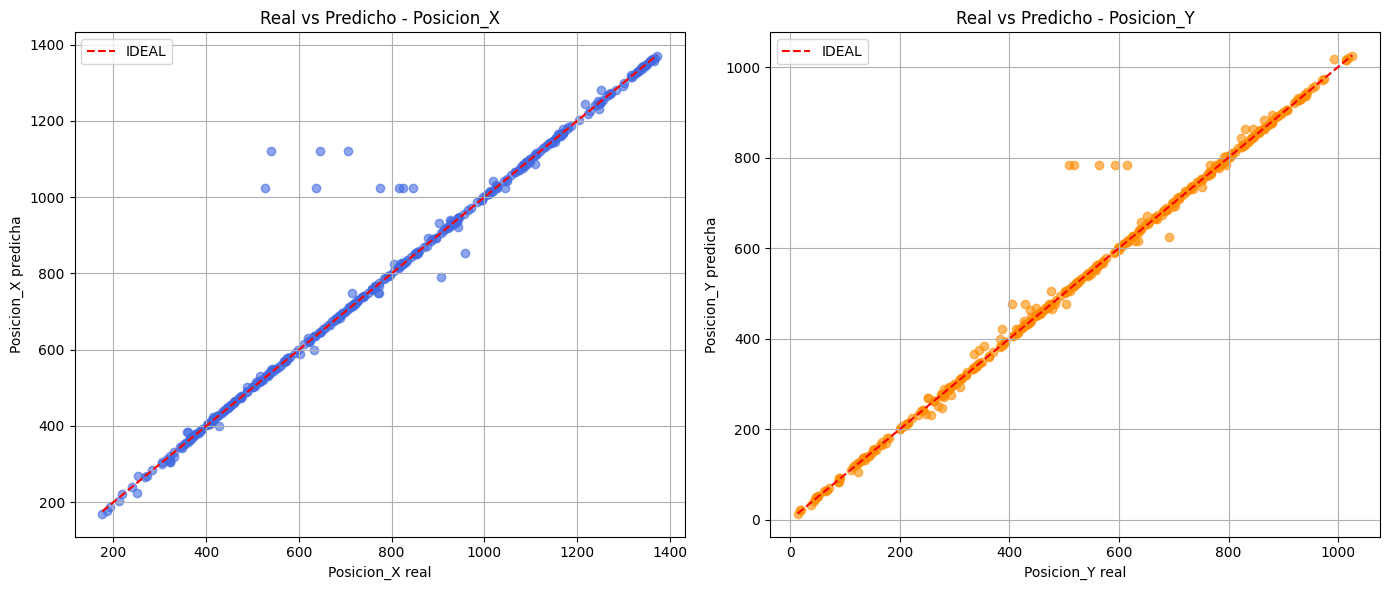

In [86]:
plt.figure(figsize=(14,6))

# ----- X -----
plt.subplot(1,2,1)
plt.scatter(data_df['Posicion_X'], data_df['Posicion_Xpred'], alpha=0.6, color='royalblue')
plt.plot([data_df['Posicion_X'].min(), data_df['Posicion_X'].max()],
         [data_df['Posicion_X'].min(), data_df['Posicion_X'].max()],
         'r--', label='IDEAL')
plt.xlabel('Posicion_X real')
plt.ylabel('Posicion_X predicha')
plt.title('Real vs Predicho - Posicion_X')
plt.legend()
plt.grid(True)

# ----- Y -----
plt.subplot(1,2,2)
plt.scatter(data_df['Posicion_Y'], data_df['Posicion_Ypred'], alpha=0.6, color='darkorange')
plt.plot([data_df['Posicion_Y'].min(), data_df['Posicion_Y'].max()],
         [data_df['Posicion_Y'].min(), data_df['Posicion_Y'].max()],
         'r--', label='IDEAL')
plt.xlabel('Posicion_Y real')
plt.ylabel('Posicion_Y predicha')
plt.title('Real vs Predicho - Posicion_Y')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


###1.1.2 DBSCAN

data_df al entrar al bloque DBSCAN: 381 filas
DATA_FILTER_OUTLIERS = False -> DBSCAN outlier filtering skipped.


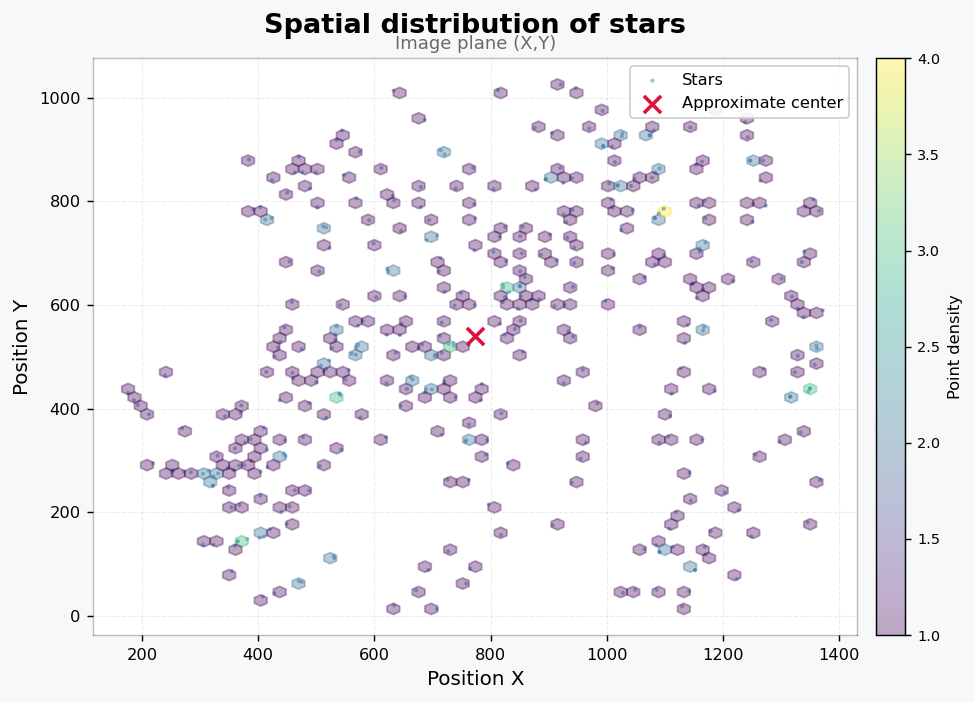

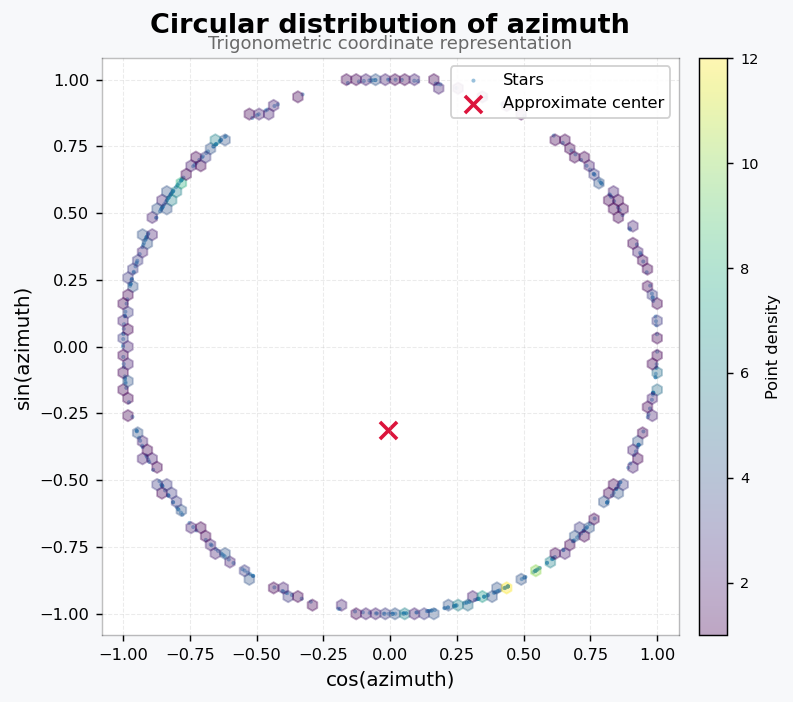


Final dataset size: 381 points (removed: 0)


In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# ==========================================
# PRE: fill in missing columns
# ==========================================
def agregar_columnas_derivadas(data):
    data = data.copy()

    if 'Nombre' not in data.columns:
        data['Nombre'] = 'no name'

    if 'zenith' not in data.columns:
        if 'altitude' in data.columns:
            data['zenith'] = 90.0 - data['altitude']
        else:
            print("Warning: neither 'zenith' nor 'altitude' exist.")

    if ('azimuth_sin' not in data.columns) or ('azimuth_cos' not in data.columns):
        if 'azimuth' in data.columns:
            theta = np.deg2rad(data['azimuth'].astype(float))
            data['azimuth_sin'] = np.sin(theta)
            data['azimuth_cos'] = np.cos(theta)
        else:
            print("Warning: 'azimuth' does not exist.")

    return data


# ==========================================
# IMPROVED PLOT
# ==========================================
def plot_Stars(dataframe, TASK="A", max_labels=5000):
    if TASK == "A":
        xcol, ycol = 'Posicion_X', 'Posicion_Y'
        xlabel, ylabel = 'Position X', 'Position Y'
        title = 'Spatial distribution of stars'
        subtitle = 'Image plane (X,Y)'

    elif TASK == "B":
        xcol, ycol = 'azimuth_cos', 'azimuth_sin'
        xlabel, ylabel = 'cos(azimuth)', 'sin(azimuth)'
        title = 'Circular distribution of azimuth'
        subtitle = 'Trigonometric coordinate representation'

    else:
        raise ValueError("TASK must be 'A' or 'B'.")

    faltan = [c for c in [xcol, ycol] if c not in dataframe.columns]
    if faltan:
        raise ValueError(f"Missing columns: {faltan}")

    x = dataframe[xcol].astype(float)
    y = dataframe[ycol].astype(float)

    fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)

    fig.patch.set_facecolor("#f7f8fa")
    ax.set_facecolor("#ffffff")

    ax.scatter(
        x, y,
        s=5,
        alpha=0.45,
        color="#1f77b4",
        edgecolors="none",
        label="Stars"
    )

    hb = ax.hexbin(
        x, y,
        gridsize=55,
        cmap="viridis",
        mincnt=1,
        alpha=0.35
    )

    cbar = fig.colorbar(hb, ax=ax, pad=0.02)
    cbar.set_label("Point density", fontsize=9)
    cbar.ax.tick_params(labelsize=8)

    ax.scatter(
        np.median(x),
        np.median(y),
        s=90,
        color="crimson",
        marker="x",
        linewidths=2,
        label="Approximate center"
    )

    ax.set_title(title, fontsize=15, fontweight="bold", pad=14)

    ax.text(
        0.5, 1.01,
        subtitle,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        color="dimgray"
    )

    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)

    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.25)

    for spine in ax.spines.values():
        spine.set_alpha(0.25)

    ax.tick_params(axis="both", labelsize=9)

    ax.legend(
        loc="upper right",
        frameon=True,
        framealpha=0.9,
        fontsize=9
    )

    if TASK == "B":
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlim(-1.08, 1.08)
        ax.set_ylim(-1.08, 1.08)

    plt.tight_layout()
    plt.show()


# ==========================================
# min_samples adaptativo segun N
# ==========================================
DBSCAN_N_REF = 363
DBSCAN_MIN_SAMPLES_REF = 25

def compute_adaptive_min_samples(n, n_ref=DBSCAN_N_REF, min_samples_ref=DBSCAN_MIN_SAMPLES_REF,
                                  min_samples_floor=5, min_samples_ceiling=150):
    scaled = min_samples_ref * (n / n_ref)
    return int(np.clip(round(scaled), min_samples_floor, min_samples_ceiling))


# ==========================================
# DBSCAN
# ==========================================
def detectar_ruido_dbscan(
    df,
    TASK="A",
    eps=0.35,
    min_samples=None,
    eliminar_outliers=True
):
    df = df.copy()
    n_in = len(df)

    if TASK == "A":
        cols = ['Posicion_X', 'Posicion_Y']
    elif TASK == "B":
        cols = ['azimuth_sin', 'azimuth_cos', 'zenith']
    else:
        raise ValueError("TASK must be 'A' or 'B'.")

    if min_samples is None:
        min_samples = compute_adaptive_min_samples(n_in)

    X = df[cols].astype(float).values
    Xs = StandardScaler().fit_transform(X)

    db = DBSCAN(eps=eps, min_samples=min_samples)
    labels = db.fit_predict(Xs)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    pct_noise = 100 * n_noise / n_in if n_in > 0 else 0.0

    print(f"[DBSCAN][{TASK}] cols={cols}")
    print(f"[DBSCAN][{TASK}] n_in={n_in}  eps={eps}  min_samples adaptativo usado={min_samples}")
    print(f"[DBSCAN][{TASK}] clusters encontrados={n_clusters}  puntos marcados ruido={n_noise} ({pct_noise:.2f}%)")

    df['cluster'] = labels
    df['is_noise'] = (labels == -1)

    df_eliminados = df[df['is_noise']].copy()
    df_limpio = df[~df['is_noise']].copy()

    print(f"[DBSCAN][{TASK}] n_out (despues de filtrar)={len(df_limpio)}\n")

    if eliminar_outliers:
        return df_limpio.reset_index(drop=True), df_eliminados.reset_index(drop=True), cols
    else:
        return df.reset_index(drop=True), df_eliminados.reset_index(drop=True), cols


# ==========================================
# PIPELINE
# NUEVO: Paso B (azimut/cenit) queda SOLO como diagnostico/plot, ya NO
# elimina puntos. Los datos de azimut/cenit forman una franja continua
# sobre el circulo unitario con densidad despareja; con min_samples alto
# DBSCAN marcaba como "ruido" tramos enteros de azimuts legitimos, no
# outliers reales (esos mismos datos se usan sin problema en estacion
# unica). Solo el Paso A (posicion de pixel X/Y), donde SI se ve un punto
# aislado real, sigue eliminando.
# ==========================================
def pipeline_dbscan_doble_paso(
    data_df,
    eps_A=0.35,
    min_samples_A=None,
    eps_B=0.35,
    min_samples_B=None,
    graficar=True,
    max_labels=5000
):
    df0 = agregar_columnas_derivadas(data_df)
    n0 = len(df0)
    print(f"\n=== INICIO PIPELINE DBSCAN ===")
    print(f"Puntos iniciales (antes de cualquier filtro): {n0}\n")

    if graficar:
        plot_Stars(df0, TASK="A")

    print("--- PASO A: filtro sobre Posicion_X / Posicion_Y (elimina) ---")
    dfA, elimA, _ = detectar_ruido_dbscan(
        df0, TASK="A",
        eps=eps_A,
        min_samples=min_samples_A
    )
    print(f"Resumen Paso A: n_in={n0} -> eliminados={len(elimA)} -> n_out={len(dfA)}\n")

    if graficar:
        plot_Stars(dfA, TASK="A")

    if graficar:
        plot_Stars(dfA, TASK="B")

    print("--- PASO B: azimuth_sin / azimuth_cos / zenith (SOLO DIAGNOSTICO, no elimina) ---")
    dfB_diag, elimB_diag, _ = detectar_ruido_dbscan(
        dfA, TASK="B",
        eps=eps_B,
        min_samples=min_samples_B,
        eliminar_outliers=False   # NUEVO: no se usa para filtrar, solo para ver clusters/ruido
    )
    print(f"[INFO] Paso B hubiera marcado {len(elimB_diag)} puntos como ruido, pero NO se eliminan "
          f"(la franja de azimut es continua y ese 'ruido' corresponde a zonas de menor densidad, no a outliers reales).\n")

    # dfB es igual a dfA: el resultado final del pipeline ya no depende del Paso B
    dfB = dfA.copy()
    elimB = pd.DataFrame()

    if graficar:
        plot_Stars(dfB, TASK="B")

    total_eliminados = len(elimA) + len(elimB)
    pct_total = 100 * total_eliminados / n0 if n0 > 0 else 0.0

    print("\nOutlier filtering summary\n-------------------------")
    print(f"Initial points:                      {n0}")
    print(f"Removed in position space (Task A):  {len(elimA)}  ({100*len(elimA)/n0:.2f}% of initial)")
    print(f"Removed in azimuth space (Task B):   {len(elimB)}  (disabled, diagnostico solamente)")
    print(f"Total removed:                        {total_eliminados}  ({pct_total:.2f}% of initial)")
    print(f"Remaining points:                    {len(dfB)}  ({100*len(dfB)/n0:.2f}% of initial)")

    return dfB, elimA, elimB


# =========================
# USE
# =========================
print(f"data_df al entrar al bloque DBSCAN: {len(data_df)} filas")

if DATA_FILTER_OUTLIERS:
    df_final, elimA, elimB = pipeline_dbscan_doble_paso(
        data_df,
        eps_A=0.35,
        min_samples_A=None,
        eps_B=0.35,
        min_samples_B=None,
        graficar=True
    )
else:
    print("DATA_FILTER_OUTLIERS = False -> DBSCAN outlier filtering skipped.")
    df_final = agregar_columnas_derivadas(data_df)
    elimA, elimB = pd.DataFrame(), pd.DataFrame()

    plot_Stars(df_final, TASK="A")
    plot_Stars(df_final, TASK="B")

print(f"\nFinal dataset size: {len(df_final)} points "
      f"(removed: {len(elimA) + len(elimB)})")

In [88]:
data_df = df_final
print(len(data_df))

381


In [89]:
list(data_df.columns)

['año',
 'Posicion_Y',
 'Posicion_X',
 'altitude',
 'Posicion_Ypred',
 'Posicion_Xpred',
 'csv',
 'd_center',
 'angle',
 'mes_sin',
 'mes_cos',
 'station_20',
 'station_1',
 'station_2',
 'station_3',
 'station_4',
 'station_5',
 'station_6',
 'station_7',
 'station_8',
 'station_9',
 'station_10',
 'station_12',
 'station_13',
 'station_14',
 'station_15',
 'station_16',
 'station_17',
 'station_19',
 'azimuth_sin',
 'azimuth_cos',
 'Nombre',
 'zenith']

### 1.1.3. Split TRAIN / TEST data


El código utiliza train_test_split de Scikit-learn para dividir el conjunto de datos data_df en dos partes: 80% para entrenamiento (train_df) y 20% para prueba (test_df), según el valor de TEST_SIZE

In [90]:
USE_PRED_AS_FEATURES = False  # True si querés incluir Posicion_Xpred/Posicion_Ypred en X

# =========================
# DATA
# =========================
df = data_df  # usás tu DF tal cual

# =========================
# FEATURES / TARGETS (solo definiciones)
# =========================
station_cols = [
    'station_1','station_2','station_3','station_4','station_5','station_6','station_7','station_8',
    'station_9','station_10','station_12','station_13','station_14','station_15','station_16','station_17',
    'station_19','station_20'
]

# Features numéricas "reales" + mes cíclico + estación one-hot
X_cols = [
    'año',
    'mes_sin', 'mes_cos',
    'd_center',
    'angle',
    'altitude',
] + station_cols

# (Opcional) incluir predicciones previas como features
if USE_PRED_AS_FEATURES:
    X_cols += ['Posicion_Xpred', 'Posicion_Ypred']

# Targets
if TASK == "A":
    y_cols = ['Posicion_X', 'Posicion_Y']
elif TASK == "B":
    y_cols = ['azimuth', 'zenith']
else:
    raise ValueError("TASK debe ser 'A' o 'B'.")

# =========================
# OUTPUT (solo info)
# =========================
print("\nX_cols (features):", X_cols)
print("y_cols (targets): ", y_cols)




X_cols (features): ['año', 'mes_sin', 'mes_cos', 'd_center', 'angle', 'altitude', 'station_1', 'station_2', 'station_3', 'station_4', 'station_5', 'station_6', 'station_7', 'station_8', 'station_9', 'station_10', 'station_12', 'station_13', 'station_14', 'station_15', 'station_16', 'station_17', 'station_19', 'station_20']
y_cols (targets):  ['Posicion_X', 'Posicion_Y']


##1.2. Preparación de datos y carga

Selección de variables de entrada y de salida según la tarea definida (TASK A o TASK B).

Codificación temporal del mes mediante una representación cíclica (mes_sin, mes_cos).

Codificación de la estación mediante representación one-hot (station_*).

División del conjunto de datos en entrenamiento y prueba utilizando una semilla fija para garantizar reproducibilidad.

Normalización de las variables continuas mediante estandarización (media = 0, desviación estándar = 1).

Aplicación opcional de aumento de datos mediante la adición de ruido gaussiano sobre variables continuas.

Aplicación opcional de filtrado de valores atípicos (outliers) utilizando el criterio de z-score aplicado por filas.

Construcción de los objetos Dataset y DataLoader de PyTorch para el entrenamiento y la evaluación del modelo.

In [91]:
# =========================
# DATAFRAME BASE
# =========================
df = data_df.copy()

# =========================
# COLUMNAS DERIVADAS (NUEVAS)
# =========================
# zenith desde altitude si falta
if 'zenith' not in df.columns:
    if 'altitude' in df.columns:
        df['zenith'] = 90.0 - df['altitude'].astype(float)
    else:
        raise ValueError("No existe 'zenith' ni 'altitude'. Necesito una de las dos.")

# azimuth_sin/cos desde azimuth (necesario para TASK A y B)
if ('azimuth_sin' not in df.columns) or ('azimuth_cos' not in df.columns):
    if 'azimuth' in df.columns:
        theta = np.deg2rad(df['azimuth'].astype(float))
        df['azimuth_sin'] = np.sin(theta)
        df['azimuth_cos'] = np.cos(theta)
    else:
        raise ValueError("No existe 'azimuth'. No se puede construir azimuth_sin/cos.")


# =========================
# COLUMNAS BASE (features comunes)
# =========================
# NOTA: 'altitude' NO se incluye acá a propósito.
# zenith = 90 - altitude (ver arriba), así que si 'altitude' fuera un input
# el modelo tendría la respuesta de 'zenith' filtrada directamente como feature.
BASE_FEATURES = [
    'd_center',
    'angle',
    'año',
    'mes_sin',
    'mes_cos'
]

# =========================
# INPUT / TARGET según TASK
# =========================
if TASK == "A":
    # (X,Y) -> (azimuth circular, zenith)
    COLUMNS_DATA   = ['Posicion_X', 'Posicion_Y'] + BASE_FEATURES + STATION_ONEHOT_COLS
    COLUMNS_TARGET = ['azimuth_sin', 'azimuth_cos', 'zenith']

elif TASK == "B":
    # (azimuth circular, zenith) -> (X,Y)
    COLUMNS_DATA   = ['azimuth_sin', 'azimuth_cos', 'zenith'] + BASE_FEATURES + STATION_ONEHOT_COLS
    COLUMNS_TARGET = ['Posicion_X', 'Posicion_Y']

else:
    raise ValueError("TASK debe ser 'A' o 'B'.")

OUTPUT_SIZE = len(COLUMNS_TARGET)

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)


# =========================
# DF MODEL (features + targets + metadata)
# =========================
df_model = df[COLUMNS_DATA + COLUMNS_TARGET].copy()  # +['Nombre', 'csv']


# =========================
# NUEVO: identificar la estación de cada fila a partir del one-hot
# - 'station' original ya no existe (se reemplazó por dummies en 1.1.1).
# - Se usa para (a) estratificar los splits y (b) ajustar el modelo
#   clasico POR ESTACION en vez de uno global mezclando camaras distintas.
# =========================
def get_station_series(dataframe, station_cols):
    sub = dataframe[station_cols]
    has_station = (sub.sum(axis=1) > 0)
    station_id = sub.idxmax(axis=1)
    station_id = station_id.where(has_station, other='UNKNOWN')
    return station_id


# =========================
# SPLIT TRAIN / TEST
# NUEVO: estratificado por estación cuando es posible (importante en
# multi-estación, para que cada camara este representada proporcionalmente
# en train/val/test). Si alguna estación tiene muy pocas muestras para
# estratificar, sklearn tira ValueError y hacemos fallback a split simple.
# =========================
station_id_all = get_station_series(df_model, STATION_ONEHOT_COLS)

try:
    train_df, test_df = train_test_split(
        df_model,
        test_size=SPLIT_TRAIN_TEST,
        random_state=RANDOM_SEED,
        stratify=station_id_all
    )
except ValueError as e:
    print(f"[WARN] No se pudo estratificar por estación en el split TRAIN/TEST "
          f"({e}). Se usa split aleatorio simple.")
    train_df, test_df = train_test_split(
        df_model,
        test_size=SPLIT_TRAIN_TEST,
        random_state=RANDOM_SEED
    )

# =========================
# SPLIT TRAIN / VALIDATION
# - Separamos una parte del TRAIN para validación.
# - Se usa para decidir el early stopping y el "mejor modelo"
#   en vez de usar la loss de TRAIN (que no detecta sobreajuste).
# - TEST queda intacto como held-out final, nunca se toca.
# - NUEVO: también estratificado por estación, mismo criterio que arriba.
# =========================
SPLIT_VAL = 0.2  # fracción del TRAIN que va a validación

station_id_train = get_station_series(train_df, STATION_ONEHOT_COLS)

try:
    train_df, val_df = train_test_split(
        train_df,
        test_size=SPLIT_VAL,
        random_state=RANDOM_SEED,
        stratify=station_id_train
    )
except ValueError as e:
    print(f"[WARN] No se pudo estratificar por estación en el split TRAIN/VAL "
          f"({e}). Se usa split aleatorio simple.")
    train_df, val_df = train_test_split(
        train_df,
        test_size=SPLIT_VAL,
        random_state=RANDOM_SEED
    )

train_df.reset_index(drop=True, inplace=True)
val_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape: ", test_df.shape)


# =========================
# AJUSTE CLASICO (previo, opcional)
# - Se ajusta SOLO con TRAIN, sobre los datos CRUDOS (antes de normalizar).
# - NUEVO: zenith_clasico y azimuth_clasico se ajustan POR ESTACION cuando
#   AJUSTE_CLASICO_POR_ESTACION=True (cada cámara tiene su propia distorsión
#   óptica y su propia orientación de montaje, así que un único ajuste
#   global mezclando todas las camaras introduce sesgo sistemático por
#   cámara). Si una estación tiene muy pocos puntos en TRAIN, se usa como
#   respaldo un ajuste GLOBAL calculado con todos los datos de TRAIN. Con
#   AJUSTE_CLASICO_POR_ESTACION=False se vuelve al comportamiento anterior
#   (un unico ajuste global para todas las estaciones).
# - Si AJUSTE_CLASICO=True, los targets se reemplazan por el RESIDUO
#   (real - clasico); si False, no se toca nada (igual que antes).
# - NUEVO (FINE_TUNING): si FINE_TUNING=True y ESTACION no es 'global', en
#   vez de recalcular el ajuste clasico con los datos de esta estación sola
#   (que caerian en un split TRAIN/VAL/TEST distinto al de la corrida
#   global), se reusa el ajuste clasico POR ESTACION que quedo guardado en
#   memoria de la ultima corrida con ESTACION='global'. Asi el modelo
#   fine-tuneado ve residuos calculados de la misma manera que cuando
#   aprendio sus pesos originales.
# =========================
classical_pred = {}  # guarda las predicciones clasicas de train/val/test (para sumarlas de vuelta en la evaluacion)

if AJUSTE_CLASICO:

    if FINE_TUNING and str(ESTACION).strip().lower() != 'global':
        if 'GLOBAL_zenith_coefs_by_station' not in globals():
            raise RuntimeError(
                "FINE_TUNING=True pero no hay ajuste clasico global guardado en memoria. "
                "Corré primero esta misma celda con ESTACION='global' (sin reiniciar el runtime)."
            )
        zenith_coefs_global      = GLOBAL_zenith_coefs_global
        azimuth_offset_global    = GLOBAL_azimuth_offset_global
        zenith_coefs_by_station  = GLOBAL_zenith_coefs_by_station
        azimuth_offset_by_station = GLOBAL_azimuth_offset_by_station
        print("[AJUSTE_CLASICO][FINE_TUNING] Usando el ajuste clasico guardado de la corrida "
              "global (no se recalcula con los datos de esta estación).")

    else:
        station_train = get_station_series(train_df, STATION_ONEHOT_COLS)

        r_train      = train_df['d_center'].values.astype(float).copy()
        angle_train  = train_df['angle'].values.astype(float).copy()
        zenith_train = train_df['zenith'].values.astype(float).copy()
        azsin_train  = train_df['azimuth_sin'].values.astype(float).copy()
        azcos_train  = train_df['azimuth_cos'].values.astype(float).copy()
        azimuth_train_deg = np.rad2deg(np.arctan2(azsin_train, azcos_train)) % 360.0

        # ---- Ajuste GLOBAL de respaldo (para estaciones con pocos datos, para
        #      estaciones nuevas que aparezcan en val/test sin datos en train, o
        #      directamente como unico ajuste si AJUSTE_CLASICO_POR_ESTACION=False) ----
        zenith_coefs_global = np.polyfit(r_train, zenith_train, deg=AJUSTE_CLASICO_GRADO)
        delta_rad_global = np.deg2rad(azimuth_train_deg - angle_train)
        offset_rad_global = np.arctan2(np.mean(np.sin(delta_rad_global)), np.mean(np.cos(delta_rad_global)))
        azimuth_offset_global = np.rad2deg(offset_rad_global)

        print(f"[AJUSTE_CLASICO][GLOBAL respaldo] zenith: polinomio grado {AJUSTE_CLASICO_GRADO}, "
              f"coefs={np.round(zenith_coefs_global, 5)} | azimuth offset={azimuth_offset_global:.3f} deg")

        # ---- Ajuste POR ESTACION (solo si AJUSTE_CLASICO_POR_ESTACION=True) ----
        zenith_coefs_by_station = {}
        azimuth_offset_by_station = {}

        if AJUSTE_CLASICO_POR_ESTACION:
            MIN_PUNTOS_AJUSTE_ESTACION = max(5, (AJUSTE_CLASICO_GRADO + 1) * 3)

            for st in station_train.unique():
                m = (station_train.values == st)
                n_st = int(m.sum())

                if n_st < 5:
                    print(f"[AJUSTE_CLASICO][{st}] Solo {n_st} puntos: se usa el ajuste GLOBAL de respaldo.")
                    continue

                # si hay pocos puntos para el grado configurado, se baja a un ajuste lineal
                grado_st = AJUSTE_CLASICO_GRADO if n_st >= MIN_PUNTOS_AJUSTE_ESTACION else 1

                zenith_coefs_by_station[st] = np.polyfit(r_train[m], zenith_train[m], deg=grado_st)

                delta_rad_st = np.deg2rad(azimuth_train_deg[m] - angle_train[m])
                offset_rad_st = np.arctan2(np.mean(np.sin(delta_rad_st)), np.mean(np.cos(delta_rad_st)))
                azimuth_offset_by_station[st] = np.rad2deg(offset_rad_st)

                print(f"[AJUSTE_CLASICO][{st}] n={n_st} | zenith: grado {grado_st}, "
                      f"coefs={np.round(zenith_coefs_by_station[st], 5)} | "
                      f"azimuth offset={azimuth_offset_by_station[st]:.3f} deg")
        else:
            print("[AJUSTE_CLASICO] AJUSTE_CLASICO_POR_ESTACION=False: "
                  "se usa un unico ajuste GLOBAL para todas las estaciones (comportamiento anterior).")

        if AJUSTE_CLASICO_POR_ESTACION:
            print(f"[AJUSTE_CLASICO] Ajuste por estación listo. "
                  f"Estaciones con modelo propio: {list(zenith_coefs_by_station.keys())}. "
                  f"El resto usa el ajuste global de respaldo.")

        # si esta corrida es la global, guardamos el ajuste en memoria para
        # poder reusarlo despues en una corrida de fine-tuning
        if str(ESTACION).strip().lower() == 'global':
            GLOBAL_zenith_coefs_global   = zenith_coefs_global
            GLOBAL_azimuth_offset_global = azimuth_offset_global
            GLOBAL_zenith_coefs_by_station   = dict(zenith_coefs_by_station)
            GLOBAL_azimuth_offset_by_station = dict(azimuth_offset_by_station)
            print("[AJUSTE_CLASICO] Guardado en memoria (GLOBAL_*) para uso posterior en fine-tuning.")

    def zenith_classico(r, station):
        coefs = zenith_coefs_by_station.get(station, zenith_coefs_global)
        return np.polyval(coefs, r)

    def azimuth_classico(angle, station):
        offset = azimuth_offset_by_station.get(station, azimuth_offset_global)
        return (angle + offset) % 360.0

    # ---- Aplicar a TRAIN / VAL / TEST y reemplazar targets por residuos ----
    for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:

        station_split = get_station_series(split_df, STATION_ONEHOT_COLS)
        r_raw   = split_df['d_center'].values.astype(float).copy()
        ang_raw = split_df['angle'].values.astype(float).copy()

        zen_clasico    = np.array([
            zenith_classico(r, st) for r, st in zip(r_raw, station_split.values)
        ])
        az_clasico_deg = np.array([
            azimuth_classico(a, st) for a, st in zip(ang_raw, station_split.values)
        ])
        az_clasico_rad = np.deg2rad(az_clasico_deg)
        azsin_clasico  = np.sin(az_clasico_rad)
        azcos_clasico  = np.cos(az_clasico_rad)

        # guardamos las predicciones clasicas para poder sumarlas de vuelta despues
        classical_pred[split_name] = {
            'zenith_classical'      : zen_clasico,
            'azimuth_sin_classical' : azsin_clasico,
            'azimuth_cos_classical' : azcos_clasico,
        }

        # targets -> residuo (real - clasico)
        split_df['zenith']       = split_df['zenith'].values.astype(float)       - zen_clasico
        split_df['azimuth_sin']  = split_df['azimuth_sin'].values.astype(float)  - azsin_clasico
        split_df['azimuth_cos']  = split_df['azimuth_cos'].values.astype(float)  - azcos_clasico

    print("[AJUSTE_CLASICO] Targets reemplazados por residuos (real - clasico).")

else:
    print("[AJUSTE_CLASICO] Desactivado: la red aprende azimuth/zenith directamente (comportamiento original, sin cambios).")


# =========================
# NORMALIZACIÓN
# - Escalamos SOLO inputs continuos
# - NO escalamos azimuth_sin/cos (ya están en [-1, 1])
# - El scaler se ajusta SOLO con TRAIN (val y test solo transforman)
# - NUEVO (FINE_TUNING): si FINE_TUNING=True y ESTACION no es 'global', se
#   reusa (solo .transform) el scaler que quedo guardado en memoria de la
#   ultima corrida con ESTACION='global', en vez de fitear uno nuevo con
#   los datos de esta estación sola. Así los inputs quedan en la misma
#   escala numerica en la que el modelo global aprendio sus pesos.
# =========================
continuous_cols = [
    'd_center','angle','año','mes_sin','mes_cos',
    'Posicion_X','Posicion_Y','zenith'
    # NOTA: azimuth_sin/cos NO se agregan acá
]

cols_scale = [c for c in COLUMNS_DATA if c in continuous_cols]

# Si hay ajuste clasico, los targets ya son residuos centrados en 0: no los
# normalizamos aunque aparezcan en continuous_cols (relevante sobre todo si
# TASK == "B", donde 'zenith' pasa a ser feature en vez de target).
if AJUSTE_CLASICO:
    cols_scale = [c for c in cols_scale if c not in COLUMNS_TARGET]

scaler = None
if DATA_NORMALIZATION and len(cols_scale) > 0:

    if FINE_TUNING and str(ESTACION).strip().lower() != 'global':
        if 'GLOBAL_scaler' not in globals() or GLOBAL_scaler is None:
            raise RuntimeError(
                "FINE_TUNING=True pero no hay scaler global guardado en memoria. "
                "Corré primero esta misma celda con ESTACION='global' (sin reiniciar el runtime)."
            )
        if list(cols_scale) != list(GLOBAL_cols_scale):
            raise RuntimeError(
                f"Las columnas a escalar no coinciden con las de la corrida global "
                f"({cols_scale} vs {GLOBAL_cols_scale}). Revisar TASK/COLUMNS_DATA."
            )
        scaler = GLOBAL_scaler
        scaled_train = scaler.transform(train_df[cols_scale].values)
        scaled_val   = scaler.transform(val_df[cols_scale].values)
        scaled_test  = scaler.transform(test_df[cols_scale].values)
        print("[NORMALIZACION][FINE_TUNING] Usando el scaler guardado de la corrida global (no se re-fitea).")

    else:
        scaler = StandardScaler()

        scaled_train = scaler.fit_transform(train_df[cols_scale].values)
        scaled_val   = scaler.transform(val_df[cols_scale].values)
        scaled_test  = scaler.transform(test_df[cols_scale].values)

        if str(ESTACION).strip().lower() == 'global':
            GLOBAL_scaler     = scaler
            GLOBAL_cols_scale = list(cols_scale)
            print("[NORMALIZACION] Scaler guardado en memoria (GLOBAL_*) para uso posterior en fine-tuning.")

    for i, col in enumerate(cols_scale):
        train_df[col] = scaled_train[:, i].astype('float32')
        val_df[col]   = scaled_val[:, i].astype('float32')
        test_df[col]  = scaled_test[:, i].astype('float32')


# =========================
# DATA AUGMENTATION
# (solo sobre TRAIN)
# =========================
def augment_with_noise(arr, noise_level=0.01):
    noise = np.random.normal(loc=0.0, scale=noise_level, size=arr.shape)
    return arr + noise

if DATA_AUGMENTATION:
    no_noise_exact = {'año', 'mes_sin', 'mes_cos'}

    for col in COLUMNS_DATA:
        if col in no_noise_exact:
            continue
        if col.startswith("station_"):
            continue
        # NO meter ruido a sin/cos del azimuth
        if col in {'azimuth_sin', 'azimuth_cos'}:
            continue
        if col in continuous_cols:
            train_df.loc[:, col] = augment_with_noise(
                train_df[col].values, noise_level=0.01
            )


# =========================
# FILTRO DE OUTLIERS (POR FILAS)
# (solo sobre TRAIN)
# =========================
if DATA_FILTER_OUTLIERS:
    THRESHOLD = 3.0

    cols_z = [
        c for c in COLUMNS_DATA
        if (c in continuous_cols) and (not c.startswith("station_"))
    ]

    Z = np.abs(stats.zscore(train_df[cols_z], nan_policy='omit'))
    mask = (Z < THRESHOLD) if Z.ndim == 1 else (Z < THRESHOLD).all(axis=1)

    before = len(train_df)
    train_df = train_df.loc[mask].reset_index(drop=True)
    after = len(train_df)

    # si hay ajuste clasico, classical_pred['train'] tiene que filtrarse con
    # la MISMA mascara usada para train_df, para seguir alineado fila a fila
    # (y con el 'idx' que despues devuelve SkyDataset/evaluate_model)
    if AJUSTE_CLASICO:
        mask_np = mask.values if hasattr(mask, 'values') else np.asarray(mask)
        for k in classical_pred['train']:
            classical_pred['train'][k] = classical_pred['train'][k][mask_np]

    print(f"[INFO] Outliers filtrados: {before-after} filas removidas. Quedan {after}.")


# =========================
# LOSS PONDERADA POR TAREA
# - Se calcula ACA (no en CONFIG) porque necesita train_df y COLUMNS_TARGET
#   ya completamente procesados (con ajuste clasico, normalizacion, data
#   augmentation y filtro de outliers ya aplicados).
# - Los pesos son 1/varianza de cada componente en TRAIN, normalizados para
#   que su promedio sea 1 (mantiene la loss en una escala comparable a un
#   MSE simple, sin necesidad de retocar el learning rate del optimizer).
# =========================
if LOSS_PONDERADA_POR_TAREA:
    target_vars = train_df[COLUMNS_TARGET].values.astype(float).var(axis=0)
    loss_weights = 1.0 / np.clip(target_vars, a_min=1e-8, a_max=None)
    loss_weights = loss_weights / loss_weights.mean()

    criterion = WeightedMSELoss(loss_weights)

    print("[LOSS] Loss ponderada por tarea activada. Pesos por componente:")
    for coord, w in zip(COLUMNS_TARGET, loss_weights):
        print(f"   {coord:12s}: peso={w:.4f}  (var_train={train_df[coord].var():.6f})")
else:
    criterion = nn.MSELoss()
    print("[LOSS] Loss ponderada por tarea desactivada: se usa MSELoss simple sin ponderar.")


# =========================
# DATASET / DATALOADER
# =========================
class SkyDataset(Dataset):
    def __init__(self, dataframe, feature_columns, label_columns):
        self.df = dataframe.reset_index(drop=True)

        self.features = self.df.loc[:, feature_columns].values.astype('float32')
        self.targets  = self.df.loc[:, label_columns].values.astype('float32')

        #self.names = self.df['Nombre'].astype(str).values
        #self.csv   = self.df['csv'].astype(str).values

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return {
            'features': torch.tensor(self.features[idx]),
            'targets' : torch.tensor(self.targets[idx]),
            #'names'   : self.names[idx],
            #'csv'     : self.csv[idx],
            'idx'     : idx
        }


train_dataset = SkyDataset(train_df, COLUMNS_DATA, COLUMNS_TARGET)
val_dataset   = SkyDataset(val_df,   COLUMNS_DATA, COLUMNS_TARGET)
test_dataset  = SkyDataset(test_df,  COLUMNS_DATA, COLUMNS_TARGET)

train_loader = DataLoader(train_dataset, batch_size=BATCH, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH, shuffle=False)


# =========================
# DEBUG FINAL
# =========================
sample = train_dataset[0]
batch  = next(iter(train_loader))

print("\nCOLUMNS_DATA (features):", len(COLUMNS_DATA))
print("COLUMNS_TARGET (targets):", len(COLUMNS_TARGET))
print("Train Dataset Length:", len(train_dataset))
print("Validation Dataset Length:", len(val_dataset))
print("Test Dataset Length: ", len(test_dataset))
print("Sample features shape:", sample['features'].shape,
      "| sample targets shape:", sample['targets'].shape)
print("Batch features shape:", batch['features'].shape,
      "| batch targets shape:", batch['targets'].shape)

Train shape: (243, 28)
Validation shape: (61, 28)
Test shape:  (77, 28)
[AJUSTE_CLASICO][GLOBAL respaldo] zenith: polinomio grado 3, coefs=[-0.0000e+00  5.0000e-05  9.1730e-02  3.0301e+00] | azimuth offset=-65.095 deg
[AJUSTE_CLASICO][station_20] n=243 | zenith: grado 3, coefs=[-0.0000e+00  5.0000e-05  9.1730e-02  3.0301e+00] | azimuth offset=-65.095 deg
[AJUSTE_CLASICO] Ajuste por estación listo. Estaciones con modelo propio: ['station_20']. El resto usa el ajuste global de respaldo.
[AJUSTE_CLASICO] Targets reemplazados por residuos (real - clasico).
[LOSS] Loss ponderada por tarea activada. Pesos por componente:
   azimuth_sin : peso=1.1107  (var_train=0.911384)
   azimuth_cos : peso=1.8129  (var_train=0.558385)
   zenith      : peso=0.0763  (var_train=13.258809)

COLUMNS_DATA (features): 25
COLUMNS_TARGET (targets): 3
Train Dataset Length: 243
Validation Dataset Length: 61
Test Dataset Length:  77
Sample features shape: torch.Size([25]) | sample targets shape: torch.Size([3])
Batch

# 2. Network Dense

## 2.1. Network Dense Model

### 2.1.1. Modelos

####**Modelo Neuronal Denso**

---

cada neurona de una capa está conectada a todas las neuronas de la siguiente capa. Esto significa que la información fluye a través de todas las conexiones posibles entre capas, lo que permite capturar relaciones complejas entre las características de los datos.

In [92]:
class SkyCoordinatesModel(nn.Module):
    def __init__(self, input_size, output_size):
        super(SkyCoordinatesModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, 256),

            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, output_size)
        )

    def forward(self, x):

        return self.network(x)

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: incertidumbre vía MC-Dropout. A diferencia del modelo
        Bayesiano (que usa LayerNorm, indiferente a train/eval), este
        modelo tiene BatchNorm1d: llamar self.train() a secas activaría
        también el BatchNorm en modo batch-stats, corrompiendo sus
        estadisticas acumuladas (running_mean/running_var) como efecto
        secundario, incluso dentro de no_grad(). Por eso el modelo se deja
        en eval() (BatchNorm usa sus stats acumuladas, sin tocarlas) y se
        fuerza SOLO el Dropout a modo train, a mano.
        Devuelve (media, desvio_estandar) por muestra, igual formato que
        BayesianSkyCoordinatesModel.predict_with_uncertainty().
        """
        self.eval()
        for module in self.modules():
            if isinstance(module, nn.Dropout):
                module.train()

        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)

        self.eval()  # restaurar todo (dropout incluido) a eval limpio
        return mean, std

# Instanciar el modelo
model_dense = SkyCoordinatesModel(input_size = len(COLUMNS_DATA), output_size = OUTPUT_SIZE).to(device)
print('Model Device:', next(model_dense.parameters()).device, '\n')
print(model_dense)
# summary(model, input_size=(1,2))  # Batch size = 1, Data Shape = (2)


Model Device: cpu 

SkyCoordinatesModel(
  (network): Sequential(
    (0): Linear(in_features=25, out_features=128, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=128, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Linear(in_features=128, out_features=3, bias=True)
  )
)


####**Modelo Neuronal Bayesiano**

---

Este modelo implementa una una capa lineal bayesiana en lugar de una capa densa tradicional. Donde los pesos y los sesgos no son valores fijos, sino distribuciones probabilísticas, lo que permite capturar la incertidumbre en los parámetros del modelo y facilitar el aprendizaje bajo condiciones inciertas.








In [93]:
# --- Corrección completa (robusta y lista para usar) ---
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class BayesianLinear(nn.Module):
    def __init__(self, in_features, out_features, init_logvar=-8.0, prior_var=1.0):
        super().__init__()
        # Medias
        self.weight_mu = nn.Parameter(torch.zeros(out_features, in_features))
        self.bias_mu   = nn.Parameter(torch.zeros(out_features))
        # Varianzas log (menos extremas que -10 para permitir aprender incertidumbre)
        self.weight_logvar = nn.Parameter(torch.ones(out_features, in_features) * init_logvar)
        self.bias_logvar   = nn.Parameter(torch.ones(out_features) * init_logvar)

        # NUEVO: prior de los pesos, Normal(0, prior_var). Se usa en kl_divergence().
        self.prior_var = prior_var

    def forward(self, x):
        if self.training:
            # Reparametrización: mu + sigma * eps (solo durante el entrenamiento,
            # necesario para propagar gradientes a través del sampling)
            weight_std = torch.exp(0.5 * self.weight_logvar)
            bias_std   = torch.exp(0.5 * self.bias_logvar)

            weight = self.weight_mu + weight_std * torch.randn_like(weight_std)
            bias   = self.bias_mu   + bias_std   * torch.randn_like(bias_std)
        else:
            # En evaluación usamos la media de la posterior (predicción determinista,
            # comparable con Dense/CNN en vez de variar en cada llamada)
            weight = self.weight_mu
            bias   = self.bias_mu

        return F.linear(x, weight, bias)

    def kl_divergence(self):
        """
        NUEVO: KL(q(w) || p(w)) entre la posterior aprendida (weight_mu,
        weight_logvar) y un prior Normal(0, prior_var), sumada sobre todos
        los pesos y bias de esta capa. Sin este término, weight_logvar no
        tiene ninguna presión hacia un prior razonable y la capa "bayesiana"
        termina siendo solo ruido de entrenamiento sin sentido probabilístico.
        """
        log_prior_var = math.log(self.prior_var)

        kl_w = 0.5 * torch.sum(
            (self.weight_mu ** 2 + torch.exp(self.weight_logvar)) / self.prior_var
            - self.weight_logvar + log_prior_var - 1.0
        )
        kl_b = 0.5 * torch.sum(
            (self.bias_mu ** 2 + torch.exp(self.bias_logvar)) / self.prior_var
            - self.bias_logvar + log_prior_var - 1.0
        )
        return kl_w + kl_b


class BayesianSkyCoordinatesModel(nn.Module):
    """
    Tronco compartido + 'heads' por salida (mejor para sesgos distintos en X e Y).
    Si output_size == 1 -> una sola head. Si >1 -> N heads y se concatenan.
    """
    def __init__(self, input_size, output_size):
        super().__init__()
        self.trunk = nn.Sequential(
            BayesianLinear(input_size, 128),
            nn.ReLU(),
            nn.LayerNorm(128),           # más estable que BatchNorm con batches chicos
            BayesianLinear(128, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
            BayesianLinear(256, 128),
            nn.ReLU(),
        )
        if output_size == 1:
            self.heads = nn.ModuleList([BayesianLinear(128, 1)])
        else:
            self.heads = nn.ModuleList([BayesianLinear(128, 1) for _ in range(output_size)])

    def forward(self, x):
        h = self.trunk(x)
        outs = [head(h) for head in self.heads]
        return torch.cat(outs, dim=1)

    def kl_divergence(self):
        """NUEVO: suma la KL de todas las capas BayesianLinear del modelo (trunk + heads)."""
        kl = 0.0
        for module in self.modules():
            if isinstance(module, BayesianLinear):
                kl = kl + module.kl_divergence()
        return kl

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: hace n_samples pasadas hacia adelante muestreando pesos
        distintos cada vez (activa el modo 'training' de las capas
        BayesianLinear aunque no se actualicen gradientes), y devuelve
        (media, desvio_estandar) por muestra. El desvio es tu estimador de
        incertidumbre por predicción, util por ejemplo para pesar cada
        observacion en la triangulación de trayectorias.
        NOTA: al llamar self.train(), el Dropout(0.30) del trunk tambien se
        activa durante el muestreo (LayerNorm no se ve afectado, no tiene
        estadisticas acumuladas como BatchNorm). Esto suma una fuente extra
        de variabilidad ademas de la incertidumbre de los pesos, lo cual es
        razonable pero vale tenerlo en cuenta al interpretar el desvio.
        """
        was_training = self.training
        self.train()
        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)
        if not was_training:
            self.eval()
        return mean, std

# Instanciación
model_Bayes = BayesianSkyCoordinatesModel(
    input_size  = len(COLUMNS_DATA),
    output_size = OUTPUT_SIZE
).to(device)

print('Model Device:', next(model_Bayes.parameters()).device, '\n')
print(model_Bayes)

Model Device: cpu 

BayesianSkyCoordinatesModel(
  (trunk): Sequential(
    (0): BayesianLinear()
    (1): ReLU()
    (2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (3): BayesianLinear()
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): BayesianLinear()
    (7): ReLU()
  )
  (heads): ModuleList(
    (0-2): 3 x BayesianLinear()
  )
)


####**Modelo Convolucional**

---
Red neuronal que usa operaciones de convolución en lugar de las conexiones totalmente conectadas típicas de las redes neuronales tradicionales. Las CNN son muy efectivas para tareas de procesamiento de imágenes, pero también se pueden aplicar a otros tipos de datos como series temporales o datos tabulares con ciertas estructuras.



In [94]:
class CNNModel(nn.Module):
    def __init__(self, input_size, output_size):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_size, out_channels=128, kernel_size=1)
        self.bn1   = nn.BatchNorm1d(128)
        self.conv2 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=1)
        self.bn2   = nn.BatchNorm1d(256)
        self.drop  = nn.Dropout(0.3)
        self.fc1   = nn.Linear(256, 128)
        self.fc2   = nn.Linear(128, output_size)

    def forward(self, x):
        x = x.unsqueeze(2)
        x = torch.relu(self.bn1(self.conv1(x)))
        x = torch.relu(self.bn2(self.conv2(x)))
        x = x.mean(dim=-1)
        x = self.drop(x)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: incertidumbre vía MC-Dropout. Igual criterio que en
        SkyCoordinatesModel (DENSE): este modelo tiene BatchNorm1d (bn1,
        bn2), así que NO se puede llamar self.train() a secas (corrompería
        las estadisticas acumuladas de BatchNorm como efecto secundario,
        incluso dentro de no_grad()). Se deja el modelo en eval() y se
        fuerza SOLO self.drop a modo train, a mano.
        Devuelve (media, desvio_estandar) por muestra, mismo formato que
        los otros dos modelos.
        """
        self.eval()
        self.drop.train()  # unico modulo de Dropout en este modelo

        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)

        self.eval()  # restaurar todo (dropout incluido) a eval limpio
        return mean, std


### 2.1.2. Configuracion

In [95]:
def get_Model(model_name, device):
    if model_name == 'DENSE':
        model = SkyCoordinatesModel(
            input_size = len(COLUMNS_DATA),
            output_size = OUTPUT_SIZE
        ).to(device)

    elif model_name == 'DENSE_BAYESIAN':
        model = BayesianSkyCoordinatesModel(
            input_size = len(COLUMNS_DATA),
            output_size = OUTPUT_SIZE
        ).to(device)

    elif model_name == 'CNN':
        model = CNNModel(
            input_size = len(COLUMNS_DATA),
            output_size = OUTPUT_SIZE
        ).to(device)

    else:
        raise ValueError(
            f"model_name '{model_name}' no reconocido. "
            "Opciones válidas: 'DENSE', 'DENSE_BAYESIAN', 'CNN'."
        )

    optimizer = optim.Adam(model.parameters(), lr=0.001)
    return model, optimizer


## 2.2. Network Training

###2.2.1 Training Function

In [96]:
# Ciclo de entrenamiento
import copy

def train_model(model, dataloader, val_dataloader, criterion, optimizer, epochs=100,
                patience=50, debug=True, beta_kl=1.0):
    """
    NUEVO: beta_kl pondera el termino de divergencia KL, que solo se suma
    cuando el modelo la tiene (model.kl_divergence(), como
    BayesianSkyCoordinatesModel) -- DENSE y CNN no tienen ese metodo, asi
    que para ellos el entrenamiento queda identico a como era antes.
    La KL total se reparte entre los minibatches de cada epoca (kl /
    n_batches), siguiendo el esquema estandar de Bayes-by-Backprop
    (Blundell et al. 2015) para que el ELBO quede bien escalado.
    """
    has_kl = hasattr(model, 'kl_divergence')
    n_batches = len(dataloader)

    loss_list, mse_list = [], []
    val_loss_list = []

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):
        # ============================
        # TRAIN
        # ============================
        model.train()
        running_loss = 0.0
        all_outputs, all_targets = [], []

        for batch in dataloader:
            inputs = batch['features'].to(device)
            targets = batch['targets'].to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            data_loss = criterion(outputs, targets)

            # NUEVO: termino KL, solo si el modelo lo soporta (Bayesiano)
            if has_kl:
                kl = model.kl_divergence()
                loss = data_loss + beta_kl * kl / n_batches
            else:
                loss = data_loss

            loss.backward()
            optimizer.step()

            # se registra solo la data_loss (comparable entre arquitecturas,
            # sin el termino de regularizacion KL)
            running_loss += data_loss.item()
            all_outputs.append(outputs.detach().cpu())
            all_targets.append(targets.detach().cpu())

        # Métricas de la época (TRAIN)
        all_outputs = torch.cat(all_outputs)
        all_targets = torch.cat(all_targets)

        mse = mean_squared_error(all_targets, all_outputs)
        mse_list.append(mse)

        epoch_loss = running_loss / len(dataloader)
        loss_list.append(epoch_loss)

        # ============================
        # VALIDATION
        # (sin termino KL: medimos precision predictiva pura, igual que en
        # DENSE/CNN, para que el early stopping y la comparacion entre
        # arquitecturas sigan siendo comparables)
        # ============================
        model.eval()
        val_running_loss = 0.0
        with torch.no_grad():
            for batch in val_dataloader:
                inputs = batch['features'].to(device)
                targets = batch['targets'].to(device)

                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_running_loss += loss.item()

        epoch_val_loss = val_running_loss / len(val_dataloader)
        val_loss_list.append(epoch_val_loss)

        # Print
        if debug and (epoch % 100 == 0 or epoch == epochs - 1):
            print(f"Epoch {epoch+1}/{epochs}, Train Loss: {epoch_loss:.4f}, "
                  f"Val Loss: {epoch_val_loss:.4f}, MSE: {mse:.4f}")

        # ============================
        # EARLY STOPPING (según VALIDATION, no TRAIN)
        # ============================
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\n⛔ Early stopping activado en epoch {epoch+1} (mejor val_loss: {best_val_loss:.4f})")
                break

    # Restaurar mejor modelo (según validación, no según train)
    if best_state is not None:
        model.load_state_dict(best_state)

    return loss_list, mse_list, val_loss_list


###2.2.2. Training Curves Plot

In [97]:
def plot_Training(mse_values, loss_values, val_loss_values=None):
    epochs = np.arange(1, len(mse_values) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico 1: MSE (train)
    axes[0].plot(epochs, mse_values, label="Train MSE", marker='o')
    axes[0].set_title("MSE per Epoch")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("MSE")
    axes[0].legend()
    axes[0].grid(True)

    # Gráfico 2: Loss (train vs validación)
    axes[1].plot(epochs, loss_values, label="Train Loss", marker='o', color='orange')
    if val_loss_values is not None:
        val_epochs = np.arange(1, len(val_loss_values) + 1)
        axes[1].plot(val_epochs, val_loss_values, label="Validation Loss", marker='o', color='green')
    axes[1].set_title("Loss per Epoch")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


## 2.3. Evaluation Utilities

###2.3.1 Metrics Calculation

In [98]:
def get_Metrics(train_eval, test_eval, model_name, debug=False):
    """
    Calcula métricas de evaluación para TRAIN y TEST.
    Requiere TASK == "A" (COLUMNS_TARGET = ['azimuth_sin', 'azimuth_cos', 'zenith']).

    Usa azimuth_from_sin_cos_deg / angular_error_deg definidas más abajo en esta
    misma sección (con las funciones de error circular / plot_error_vs_zenith),
    para no duplicar la misma lógica en dos lugares.

    Devuelve: {'TRAIN': {...}, 'TEST': {...}}, cada una con:
      - rmse_components_native_units: RMSE por salida en su unidad nativa
        (azimuth_sin/cos: adimensional | zenith: grados)
      - r2_components: R2 por salida
      - azimuth_rmse_deg / azimuth_rmse_arcmin: precisión angular real de azimuth
        (reconstruido desde sin/cos, con manejo circular correcto)
      - zenith_rmse_deg / zenith_rmse_arcmin: precisión angular de zenith
      - combined_rmse_deg: azimuth_rmse_deg + zenith_rmse_deg (criterio de selección)
      - sky_angular_rmse_deg / sky_angular_rmse_arcmin: NUEVO. Distancia angular
        real sobre el cielo entre la dirección predicha y la real (combinando
        azimuth y zenith en una sola formula esferica), no la suma de dos
        errores por separado. Se agrega porque azimuth_rmse_deg, al estar en
        grados de azimuth, se infla artificialmente cerca del cenit (donde el
        azimuth esta mal condicionado: un pixel de diferencia puede mover el
        azimuth muchos grados aunque la posicion real en el cielo casi no
        cambie). sky_angular_rmse_deg no tiene ese problema, porque mide
        directamente la separacion real en el cielo, y por eso es la metrica
        recomendada para reportar precision global.
    """
    if not {'azimuth_sin', 'azimuth_cos', 'zenith'}.issubset(set(COLUMNS_TARGET)):
        raise ValueError(
            "get_Metrics() está pensado para TASK='A' "
            "(COLUMNS_TARGET debe incluir 'azimuth_sin', 'azimuth_cos', 'zenith'). "
            f"COLUMNS_TARGET actual: {COLUMNS_TARGET}"
        )

    idx_sin    = COLUMNS_TARGET.index('azimuth_sin')
    idx_cos    = COLUMNS_TARGET.index('azimuth_cos')
    idx_zenith = COLUMNS_TARGET.index('zenith')

    metrics = {}

    for data in [train_eval, test_eval]:
        targets = data['targets'].cpu().numpy()
        labels  = data['labels'].cpu().numpy()

        # --- RMSE / R2 por componente, en unidades nativas ---
        rmse_components = {}
        r2_components = {}
        for ix, coord in enumerate(COLUMNS_TARGET):
            t = targets[:, ix]
            p = labels[:, ix]
            rmse_components[coord] = float(np.sqrt(mean_squared_error(t, p)))
            r2_components[coord]   = float(r2_score(t, p))

        # --- Azimuth real reconstruido (grados) + error circular ---
        az_true_deg = azimuth_from_sin_cos_deg(targets[:, idx_sin], targets[:, idx_cos])
        az_pred_deg = azimuth_from_sin_cos_deg(labels[:, idx_sin],  labels[:, idx_cos])
        az_err_deg  = angular_error_deg(az_true_deg, az_pred_deg)
        azimuth_rmse_deg = float(np.sqrt(np.mean(az_err_deg ** 2)))

        # --- Zenith ya está en grados directamente ---
        zenith_true_deg = targets[:, idx_zenith]
        zenith_pred_deg = labels[:, idx_zenith]
        zenith_rmse_deg = rmse_components['zenith']

        # ==========================================
        # NUEVO: distancia angular real sobre el cielo (formula de coseno
        # esferico), combinando azimuth y zenith en un solo error angular
        # que no se degenera cerca del cenit.
        # ==========================================
        zen_true_rad = np.deg2rad(zenith_true_deg)
        zen_pred_rad = np.deg2rad(zenith_pred_deg)
        az_true_rad  = np.deg2rad(az_true_deg)
        az_pred_rad  = np.deg2rad(az_pred_deg)

        cos_sep = (
            np.cos(zen_true_rad) * np.cos(zen_pred_rad)
            + np.sin(zen_true_rad) * np.sin(zen_pred_rad) * np.cos(az_true_rad - az_pred_rad)
        )
        cos_sep = np.clip(cos_sep, -1.0, 1.0)  # evitar errores numericos fuera de [-1,1]
        sky_sep_deg = np.rad2deg(np.arccos(cos_sep))

        sky_angular_rmse_deg = float(np.sqrt(np.mean(sky_sep_deg ** 2)))
        sky_angular_mae_deg  = float(np.mean(sky_sep_deg))

        metrics[data['type']] = {
            'rmse_components_native_units': rmse_components,
            'r2_components': r2_components,
            'azimuth_rmse_deg': azimuth_rmse_deg,
            'azimuth_rmse_arcmin': azimuth_rmse_deg * 60.0,
            'zenith_rmse_deg': zenith_rmse_deg,
            'zenith_rmse_arcmin': zenith_rmse_deg * 60.0,
            'combined_rmse_deg': azimuth_rmse_deg + zenith_rmse_deg,
            'sky_angular_rmse_deg': sky_angular_rmse_deg,
            'sky_angular_rmse_arcmin': sky_angular_rmse_deg * 60.0,
            'sky_angular_mae_deg': sky_angular_mae_deg,
        }

        if debug:
            print('\n', data['type'], 'DATA\n-----------')
            print('RMSE per component (native units):')
            print(f"   azimuth_sin  (dimensionless): {rmse_components['azimuth_sin']:.4f}")
            print(f"   azimuth_cos  (dimensionless): {rmse_components['azimuth_cos']:.4f}")
            print(f"   zenith       (degrees):       {rmse_components['zenith']:.4f}")
            print('R^2 per component:')
            print(f"   azimuth_sin: {r2_components['azimuth_sin']:.4f}"
                  f"   azimuth_cos: {r2_components['azimuth_cos']:.4f}"
                  f"   zenith:      {r2_components['zenith']:.4f}")
            print('Angular precision (reconstructed from sin/cos):')
            print(f"   Azimuth RMSE: {azimuth_rmse_deg:.4f} deg  ({azimuth_rmse_deg*60:.2f} arcmin)")
            print(f"   Zenith  RMSE: {zenith_rmse_deg:.4f} deg  ({zenith_rmse_deg*60:.2f} arcmin)")
            print('Sky angular separation (real distance on the sky, robust near zenith):')
            print(f"   RMSE: {sky_angular_rmse_deg:.4f} deg  ({sky_angular_rmse_deg*60:.2f} arcmin)")
            print(f"   MAE:  {sky_angular_mae_deg:.4f} deg  ({sky_angular_mae_deg*60:.2f} arcmin)")

    return metrics

###2.3.2 Prediction Scatter Plots

In [99]:
def show_Predictions(train_eval, test_eval, model_name, show_labels=False):
    # NOTA: show_labels no se usa actualmente (la lógica de anotar puntos con
    # nombre/csv está deshabilitada), se mantiene el parámetro por compatibilidad.

    print('\n', '*'*50, '\n\t', model_name, '\n', '*'*50)
    n_cols = len(COLUMNS_TARGET)
    fig, axes = plt.subplots(1, n_cols, figsize=(5*n_cols, 5))

    # Rango combinado (train+test, target+predicción) para que la diagonal
    # IDEAL cubra todo el rango visible de puntos en cada subplot
    all_targets = torch.cat([train_eval['targets'], test_eval['targets']]).cpu().numpy()
    all_labels  = torch.cat([train_eval['labels'],  test_eval['labels']]).cpu().numpy()

    diag = True
    for data in [train_eval, test_eval]:
        targets = data['targets'].cpu().numpy()
        labels  = data['labels'].cpu().numpy()

        for ix, coord in enumerate(COLUMNS_TARGET):
            if len(COLUMNS_TARGET) > 1:
                ax = axes[ix]
                target_plot = targets[:, ix]
                label_plot  = labels[:, ix]
            else:
                target_plot = targets
                label_plot  = labels
                ax = axes

            ax.set_box_aspect(1)

            if diag:
                if n_cols > 1:
                    combined = np.concatenate([all_targets[:, ix], all_labels[:, ix]])
                else:
                    combined = np.concatenate([all_targets, all_labels])
                plot_min, plot_max = np.min(combined), np.max(combined)
                ax.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label="IDEAL")

            ax.scatter(target_plot, label_plot, alpha=0.5, label=''.join([coord, ' - ', data['type']]))

            ax.set_xlabel(''.join(['Real Target - ', coord]))
            ax.set_ylabel(''.join(['Pred Labels - ', coord]))
            ax.legend()
            ax.axhline(y=0, linestyle='--', color='gray')
            ax.axvline(x=0, linestyle='--', color='gray')
            ax.set_title(f"{model_name}: {coord} - Targets vs Labels")
            ax.grid()
        diag = False

    plt.tight_layout()
    plt.show()



###2.3.3 Model Evaluation (Forward Pass)

In [100]:
# Evaluar el modelo
def evaluate_model(model, dataloader, criterion):
    model.eval()
    total_loss = 0.0
    all_outputs, all_targets, all_idx = [], [], []
    # all_names, all_csv = [], []   # COMENTADO
    with torch.no_grad():
        for batch in dataloader:
            inputs, targets = batch['features'].to(device), batch['targets'].to(device)
            # names = batch['names']   # COMENTADO
            # csv   = batch['csv']     # COMENTADO
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            total_loss += loss.item()
            all_outputs.append(outputs.detach().cpu())
            all_targets.append(targets.detach().cpu())
            # all_names.append(names)          # COMENTADO
            # all_csv.append(batch['csv'])     # COMENTADO
            all_idx.append(batch['idx'])

    data = {
        'labels'  : torch.cat(all_outputs),
        'targets' : torch.cat(all_targets),
        # 'names'   : [name for sublist in all_names for name in sublist],  # COMENTADO
        # 'csv'     : [csv for sublist in all_csv for csv in sublist],      # COMENTADO
        'loss'    : total_loss / len(dataloader),
        'idx'     : torch.cat(all_idx)
    }

    return data



###2.3.4 Circular Error Utilities & Error-vs-Zenith Plot

In [101]:
# ============================================================
# 1) Funciones: azimuth desde sin/cos + wrap + métricas
# ============================================================

def azimuth_from_sin_cos_deg(az_sin, az_cos):
    """sin/cos -> azimuth en grados [0, 360)"""
    az_sin = np.asarray(az_sin, dtype=float)
    az_cos = np.asarray(az_cos, dtype=float)
    az_rad = np.arctan2(az_sin, az_cos)
    az_deg = (np.rad2deg(az_rad) + 360.0) % 360.0
    return az_deg


def wrap_angle_deg(delta_deg):
    """Envuelve diferencia angular a [-180, 180)"""
    delta_deg = np.asarray(delta_deg, dtype=float)
    return (delta_deg + 180.0) % 360.0 - 180.0


def angular_error_deg(az_true_deg, az_pred_deg):
    """Error circular mínimo en grados (array), en [-180, 180)"""
    return wrap_angle_deg(np.asarray(az_pred_deg, float) - np.asarray(az_true_deg, float))


def angular_metrics_deg(az_true_deg, az_pred_deg):
    """MAE/RMSE/Bias en grados usando error circular mínimo (SOLO azimuth).
    OJO: esta métrica se degenera cerca del cenit (un pixel de diferencia
    puede mover el azimuth muchos grados aunque la posicion real en el
    cielo casi no cambie). Se mantiene como diagnostico de la componente
    de azimuth en si misma, pero para precision global usar
    sky_angular_metrics_deg() de mas abajo, que no tiene ese problema."""
    err = angular_error_deg(az_true_deg, az_pred_deg)
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err**2)))
    bias = float(np.mean(err))
    return {"MAE_deg": mae, "RMSE_deg": rmse, "Bias_deg": bias}


# ============================================================
# 1b) NUEVO: distancia angular real sobre el cielo (azimuth + zenith
# combinados en una sola formula esferica). No se degenera cerca del
# cenit como si lo hace el error de azimuth en grados por separado.
# ============================================================

def sky_angular_separation_deg(zenith_true_deg, zenith_pred_deg, az_true_deg, az_pred_deg):
    """
    Distancia angular real entre la direccion verdadera y la predicha
    (formula de coseno esferico), en grados. Combina azimuth y zenith en
    un solo numero que representa la separacion real en el cielo.
    """
    zen_true_rad = np.deg2rad(np.asarray(zenith_true_deg, dtype=float))
    zen_pred_rad = np.deg2rad(np.asarray(zenith_pred_deg, dtype=float))
    az_true_rad  = np.deg2rad(np.asarray(az_true_deg, dtype=float))
    az_pred_rad  = np.deg2rad(np.asarray(az_pred_deg, dtype=float))

    cos_sep = (
        np.cos(zen_true_rad) * np.cos(zen_pred_rad)
        + np.sin(zen_true_rad) * np.sin(zen_pred_rad) * np.cos(az_true_rad - az_pred_rad)
    )
    cos_sep = np.clip(cos_sep, -1.0, 1.0)  # evitar errores numericos fuera de [-1,1]
    return np.rad2deg(np.arccos(cos_sep))


def sky_angular_metrics_deg(zenith_true_deg, zenith_pred_deg, az_true_deg, az_pred_deg):
    """MAE/RMSE de la separacion angular real sobre el cielo."""
    sep = sky_angular_separation_deg(zenith_true_deg, zenith_pred_deg, az_true_deg, az_pred_deg)
    return {
        "MAE_deg": float(np.mean(sep)),
        "RMSE_deg": float(np.sqrt(np.mean(sep**2))),
    }


# ============================================================
# 2) Gráfico: error de azimuth vs zenith
# ============================================================

def plot_error_vs_zenith(
    y_true,
    y_pred,
    idx_sin=0,
    idx_cos=1,
    idx_zenith=2,
    zenith_in_degrees=True,
    title="|Azimuth error| vs Zenith",
    bins=None,           # None = se calcula automático según N (sirve para 1 estación o multi-estación)
    min_count=None,      # None = se calcula automático según N
    target_per_bin=10,   # cuántas muestras "ideales" te gustaría tener por bin
    bins_min=4,
    bins_max=18
):
    """
    y_true, y_pred: np.ndarray (N,K)
    Asume que y_true/y_pred contienen:
      - azimuth_sin en idx_sin
      - azimuth_cos en idx_cos
      - zenith en idx_zenith (grados, idealmente sin escalar)

    bins/min_count: si se dejan en None, se calculan automáticamente en
    función de cuántos puntos hay (N), para que la función funcione bien
    tanto con pocos datos (una sola estación) como con muchos (multi-estación),
    sin tener que ajustar nada a mano en cada corrida.

    Ademas del error de azimuth (que se degenera cerca del cenit), calcula
    y grafica tambien la separacion angular real sobre el cielo
    (sky_angular_separation_deg), que combina azimuth y zenith y no tiene
    ese problema.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    az_true_deg = azimuth_from_sin_cos_deg(y_true[:, idx_sin], y_true[:, idx_cos])
    az_pred_deg = azimuth_from_sin_cos_deg(y_pred[:, idx_sin], y_pred[:, idx_cos])

    err_deg = angular_error_deg(az_true_deg, az_pred_deg)
    abs_err_deg = np.abs(err_deg)

    zen_true = y_true[:, idx_zenith].astype(float)
    zen_pred = y_pred[:, idx_zenith].astype(float)

    if not zenith_in_degrees:
        print("[WARN] zenith_in_degrees=False: plotting zenith on a non-degree scale.")

    mask = np.isfinite(zen_true) & np.isfinite(zen_pred) & np.isfinite(abs_err_deg)
    zen_true_m = zen_true[mask]
    zen_pred_m = zen_pred[mask]
    abs_err_deg_m = abs_err_deg[mask]
    az_true_deg_m = az_true_deg[mask]
    az_pred_deg_m = az_pred_deg[mask]

    # NUEVO: separacion angular real sobre el cielo, por punto
    sky_sep_deg_m = sky_angular_separation_deg(zen_true_m, zen_pred_m, az_true_deg_m, az_pred_deg_m)

    N = len(zen_true_m)

    # --- bins / min_count automáticos según cuántos puntos hay ---
    if bins is None:
        bins = int(np.clip(N // target_per_bin, bins_min, bins_max))
    if min_count is None:
        min_count = max(3, target_per_bin // 3)

    met = angular_metrics_deg(az_true_deg_m, az_pred_deg_m)
    print("Global azimuth metrics (circular, degenera cerca del cenit):", met)

    sky_met = sky_angular_metrics_deg(zen_true_m, zen_pred_m, az_true_deg_m, az_pred_deg_m)
    print("Global sky angular separation (real, robusta cerca del cenit):", sky_met)

    print(f"[INFO] N={N} -> bins={bins}, min_count={min_count}")

    # ===== Scatter: azimuth error =====
    plt.figure(figsize=(9, 6))
    plt.scatter(zen_true_m, abs_err_deg_m, s=10)
    plt.xlabel("Zenith (deg)" if zenith_in_degrees else "Zenith (scaled)")
    plt.ylabel("|Azimuth error| (deg)")
    plt.title(title)
    plt.grid(True)
    plt.show()

    # ===== Scatter: sky angular separation (NUEVO) =====
    plt.figure(figsize=(9, 6))
    plt.scatter(zen_true_m, sky_sep_deg_m, s=10, color="darkgreen")
    plt.xlabel("Zenith (deg)" if zenith_in_degrees else "Zenith (scaled)")
    plt.ylabel("Sky angular separation (deg)")
    plt.title(title.replace("|Azimuth error|", "Sky angular separation"))
    plt.grid(True)
    plt.show()

    # ===== Binned curve (median and p90) =====
    if bins is not None and bins > 1:
        zmin, zmax = float(np.min(zen_true_m)), float(np.max(zen_true_m))
        edges = np.linspace(zmin, zmax, bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])

        med = np.full(bins, np.nan)
        p90 = np.full(bins, np.nan)
        med_sky = np.full(bins, np.nan)
        p90_sky = np.full(bins, np.nan)
        counts = np.zeros(bins, dtype=int)

        for i in range(bins):
            m = (zen_true_m >= edges[i]) & (zen_true_m < edges[i+1])
            counts[i] = int(np.sum(m))
            if counts[i] >= min_count:  # antes era un "10" fijo
                med[i] = np.nanmedian(abs_err_deg_m[m])
                p90[i] = np.nanpercentile(abs_err_deg_m[m], 90)
                med_sky[i] = np.nanmedian(sky_sep_deg_m[m])
                p90_sky[i] = np.nanpercentile(sky_sep_deg_m[m], 90)

        # --- binned plot: azimuth error (metrica vieja, se degenera cerca del cenit) ---
        plt.figure(figsize=(9, 6))
        plt.plot(centers, med, marker='o', label="Median |azimuth err|")
        plt.plot(centers, p90, marker='o', label="P90 |azimuth err|")
        plt.xlabel("Zenith (deg)" if zenith_in_degrees else "Zenith (scaled)")
        plt.ylabel("|Azimuth error| (deg)")
        plt.title(title + " (binned)")
        plt.grid(True)
        plt.legend()
        plt.show()

        # --- binned plot: sky angular separation (NUEVO, metrica recomendada) ---
        plt.figure(figsize=(9, 6))
        plt.plot(centers, med_sky, marker='o', color="darkgreen", label="Median sky separation")
        plt.plot(centers, p90_sky, marker='o', color="orange", label="P90 sky separation")
        plt.xlabel("Zenith (deg)" if zenith_in_degrees else "Zenith (scaled)")
        plt.ylabel("Sky angular separation (deg)")
        plt.title(title.replace("|Azimuth error|", "Sky angular separation") + " (binned)")
        plt.grid(True)
        plt.legend()
        plt.show()

        print("\nBin summary (zenith) - azimuth error (degenera cerca del cenit):")
        for i in range(bins):
            if counts[i] > 0:
                print(f"  Bin {i+1:02d}: z~{centers[i]:6.2f}  n={counts[i]:4d}  med={med[i]:6.2f}  p90={p90[i]:6.2f}")

        print("\nBin summary (zenith) - sky angular separation (robusta, recomendada):")
        for i in range(bins):
            if counts[i] > 0:
                print(f"  Bin {i+1:02d}: z~{centers[i]:6.2f}  n={counts[i]:4d}  med={med_sky[i]:6.2f}  p90={p90_sky[i]:6.2f}")

## 2.4. Simulation Loop

###2.4.1. Training Runs & Model Selection

In [102]:
import copy

# --- se sube acá para poder usarla dentro del loop (antes solo estaba definida en la celda del FINAL REPORT) ---
def to_real_eval(data):
    if not AJUSTE_CLASICO:
        return data

    idx_sin_r    = COLUMNS_TARGET.index('azimuth_sin')
    idx_cos_r    = COLUMNS_TARGET.index('azimuth_cos')
    idx_zenith_r = COLUMNS_TARGET.index('zenith')

    idx_np = data['idx'].cpu().numpy()
    cp = classical_pred[data['type'].lower()]  # 'TRAIN'/'TEST' -> 'train'/'test'

    targets = data['targets'].cpu().numpy().copy()
    labels  = data['labels'].cpu().numpy().copy()

    targets[:, idx_sin_r]    = targets[:, idx_sin_r]    + cp['azimuth_sin_classical'][idx_np]
    targets[:, idx_cos_r]    = targets[:, idx_cos_r]    + cp['azimuth_cos_classical'][idx_np]
    targets[:, idx_zenith_r] = targets[:, idx_zenith_r] + cp['zenith_classical'][idx_np]

    labels[:, idx_sin_r]    = labels[:, idx_sin_r]    + cp['azimuth_sin_classical'][idx_np]
    labels[:, idx_cos_r]    = labels[:, idx_cos_r]    + cp['azimuth_cos_classical'][idx_np]
    labels[:, idx_zenith_r] = labels[:, idx_zenith_r] + cp['zenith_classical'][idx_np]

    data_real = dict(data)
    data_real['targets'] = torch.tensor(targets)
    data_real['labels']  = torch.tensor(labels)
    return data_real
# --- fin de lo agregado ---

r2_list, rmse_list, loss_list, mse_list, val_loss_list, val_score_list = [], [], [], [], [], []
train_eval_list, test_eval_list = [], []
model_state_list = []
metrics_list = []

best_val_loss = float('inf')
best_idx = None

for loop in range(LOOPS):
    print(f"\n{'='*60}\nLOOP {loop+1}/{LOOPS}\n{'='*60}")

    model, optimizer = get_Model(model_name, device)
    loss, mse, val_loss = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=EPOCHS, beta_kl=0.01)
    # --- antes: beta_kl=0.05 ---

    test_eval = evaluate_model(model, test_loader, criterion)
    test_eval['type'] = 'TEST'
    train_eval = evaluate_model(model, train_loader, criterion)
    train_eval['type'] = 'TRAIN'

    train_eval_r = to_real_eval(train_eval)
    test_eval_r  = to_real_eval(test_eval)
    metrics = get_Metrics(train_eval_r, test_eval_r, f"Model {model_name}", debug=True)

    val_score = min(val_loss)

    loss_list.append(loss)
    mse_list.append(mse)
    val_loss_list.append(val_loss)
    val_score_list.append(val_score)
    r2_list.append(metrics['TEST']['r2_components'])
    rmse_list.append(metrics['TEST']['rmse_components_native_units'])
    train_eval_list.append(train_eval)
    test_eval_list.append(test_eval)
    metrics_list.append(metrics)
    model_state_list.append(copy.deepcopy(model.state_dict()))

    print(f"\nLoop {loop+1}: val_loss(best)={val_score:.4f} | "
          f"test angular error: azimuth={metrics['TEST']['azimuth_rmse_deg']:.4f} deg, "
          f"zenith={metrics['TEST']['zenith_rmse_deg']:.4f} deg, "
          f"combined={metrics['TEST']['combined_rmse_deg']:.4f} deg")

    if val_score < best_val_loss:
        best_val_loss = val_score
        best_idx = loop

# =========================
# SELECCIÓN DEL MEJOR LOOP (según VALIDACIÓN, no TEST)
# =========================
print(f"\n{'='*60}\nBest run: LOOP {best_idx+1}/{LOOPS} "
      f"(best val_loss = {best_val_loss:.4f})\n{'='*60}")

model.load_state_dict(model_state_list[best_idx])
loss = loss_list[best_idx]
mse = mse_list[best_idx]
val_loss = val_loss_list[best_idx]
train_eval = train_eval_list[best_idx]
test_eval = test_eval_list[best_idx]
best_metrics = metrics_list[best_idx]

print("\nSummary across loops (val_loss used for selection; test shown for reference only):")
for i, m in enumerate(metrics_list):
    s = m['TEST']['combined_rmse_deg']
    marker = "  <-- best (by val_loss)" if i == best_idx else ""
    print(f"  Loop {i+1}: val_loss={val_score_list[i]:.4f} | "
          f"test azimuth={m['TEST']['azimuth_rmse_deg']:.4f} deg, "
          f"zenith={m['TEST']['zenith_rmse_deg']:.4f} deg, combined={s:.4f} deg{marker}")


LOOP 1/5
Epoch 1/1000, Train Loss: 0.6568, Val Loss: 0.8729, MSE: 4.6366

⛔ Early stopping activado en epoch 86 (mejor val_loss: 0.2515)

 TRAIN DATA
-----------
RMSE per component (native units):
   azimuth_sin  (dimensionless): 0.1097
   azimuth_cos  (dimensionless): 0.1201
   zenith       (degrees):       1.1768
R^2 per component:
   azimuth_sin: 0.9734   azimuth_cos: 0.9725   zenith:      0.9955
Angular precision (reconstructed from sin/cos):
   Azimuth RMSE: 10.0564 deg  (603.39 arcmin)
   Zenith  RMSE: 1.1768 deg  (70.61 arcmin)
Sky angular separation (real distance on the sky, robust near zenith):
   RMSE: 5.0666 deg  (304.00 arcmin)
   MAE:  2.4127 deg  (144.76 arcmin)

 TEST DATA
-----------
RMSE per component (native units):
   azimuth_sin  (dimensionless): 0.1551
   azimuth_cos  (dimensionless): 0.2662
   zenith       (degrees):       5.6166
R^2 per component:
   azimuth_sin: 0.9420   azimuth_cos: 0.8584   zenith:      0.9005
Angular precision (reconstructed from sin/cos):


###2.4.2. Final Report & Error-vs-Zenith Plot

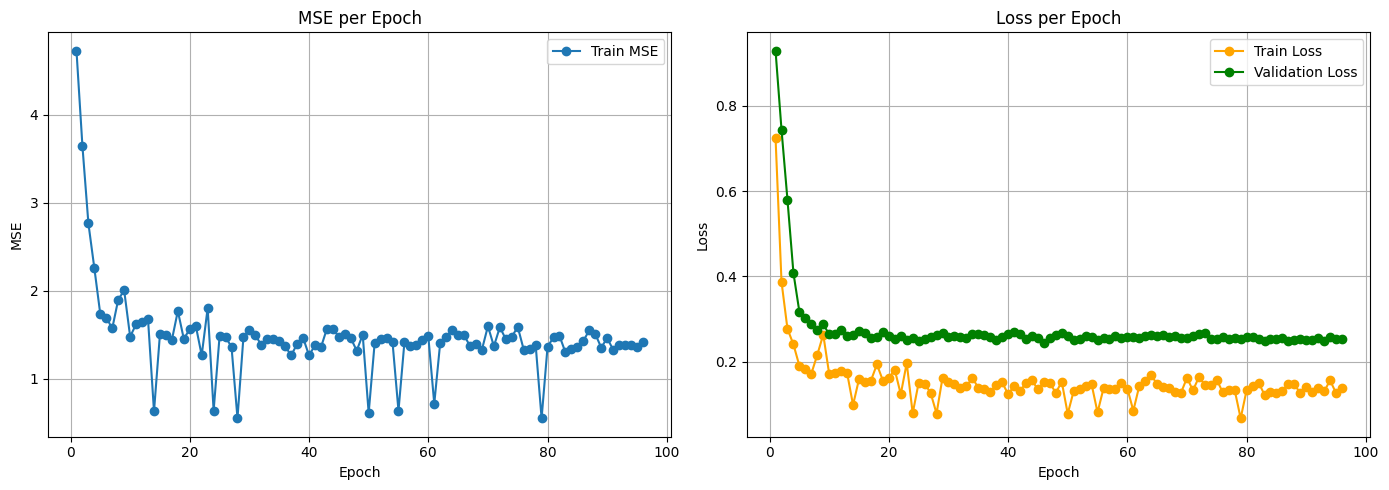


 ************************************************** 
	 Model CNN 
 **************************************************


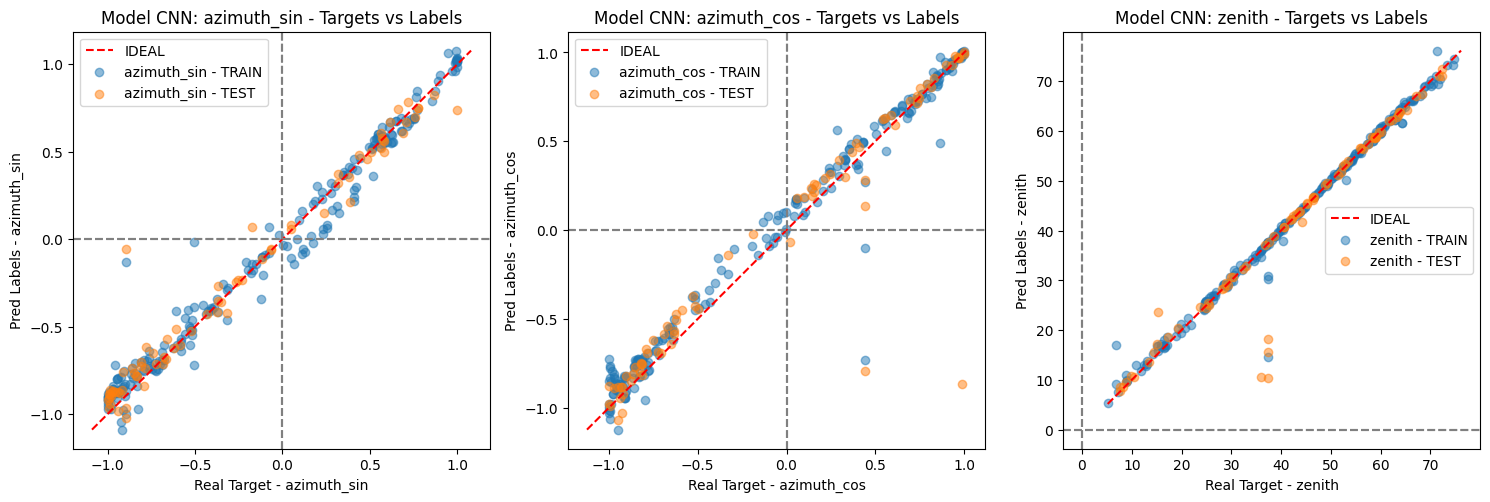


FINAL REPORT — CNN

TRAIN:
  Azimuth precision: 9.4892 deg (569.35 arcmin)
  Zenith precision:  1.9525 deg (117.15 arcmin)
  R^2 -> azimuth_sin: 0.9762, azimuth_cos: 0.9717, zenith: 0.9877

TEST:
  Azimuth precision: 24.0955 deg (1445.73 arcmin)
  Zenith precision:  5.4907 deg (329.44 arcmin)
  R^2 -> azimuth_sin: 0.9626, azimuth_cos: 0.8570, zenith: 0.9049
Global azimuth metrics (circular, degenera cerca del cenit): {'MAE_deg': 7.076157356116436, 'RMSE_deg': 24.09546898016299, 'Bias_deg': -1.926668208116498}
Global sky angular separation (real, robusta cerca del cenit): {'MAE_deg': 3.94918952426786, 'RMSE_deg': 9.010512429710856}
[INFO] N=77 -> bins=7, min_count=3


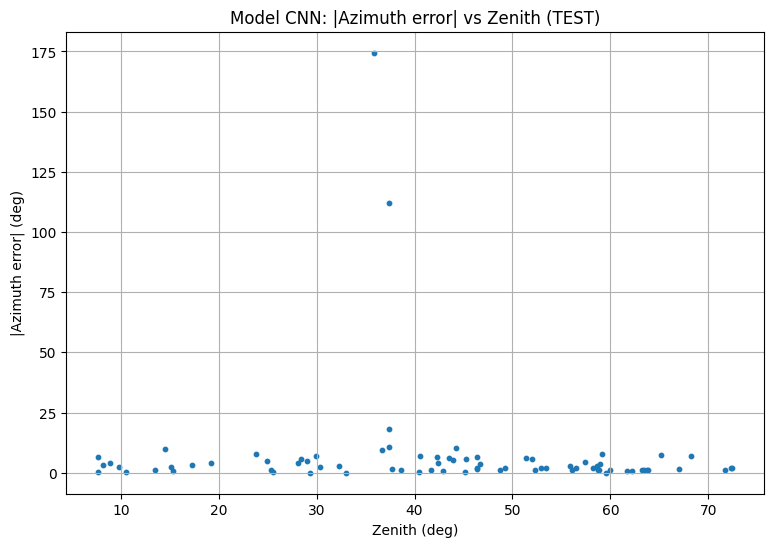

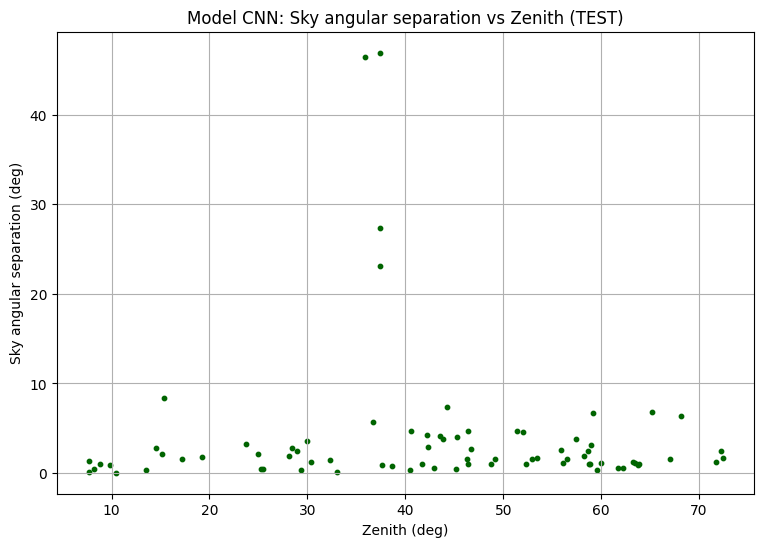

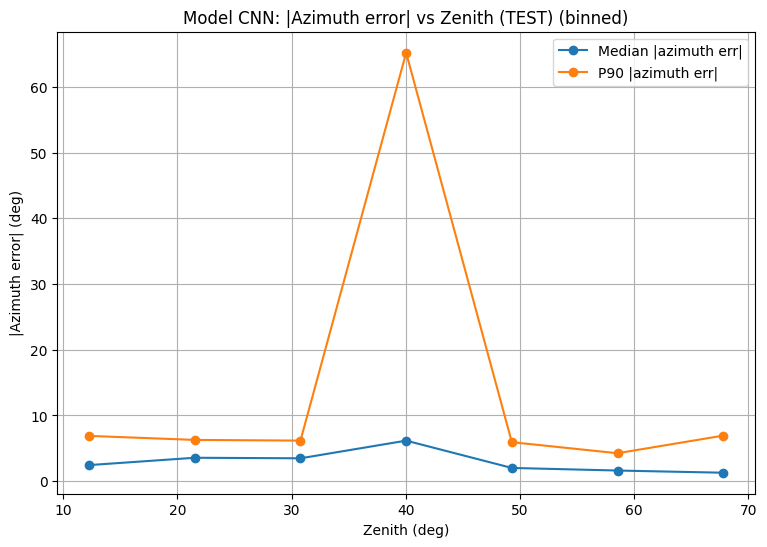

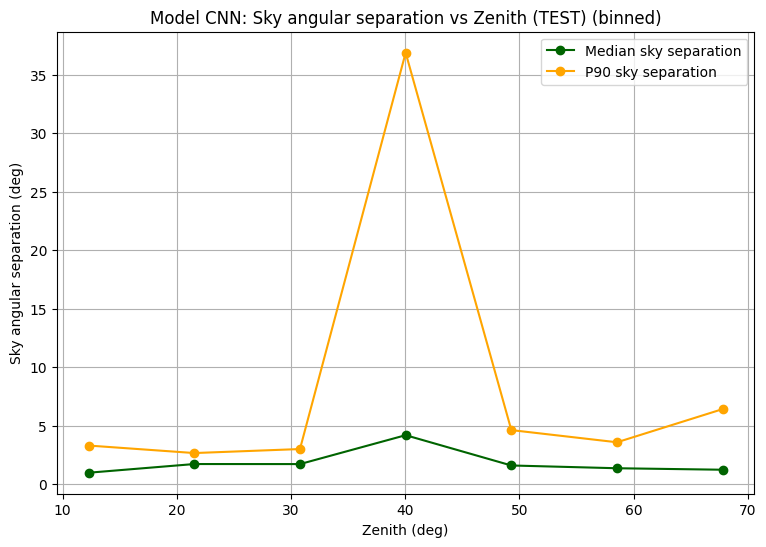


Bin summary (zenith) - azimuth error (degenera cerca del cenit):
  Bin 01: z~ 12.28  n=  10  med=  2.44  p90=  6.88
  Bin 02: z~ 21.53  n=   6  med=  3.55  p90=  6.27
  Bin 03: z~ 30.78  n=   8  med=  3.47  p90=  6.17
  Bin 04: z~ 40.04  n=  16  med=  6.16  p90= 65.21
  Bin 05: z~ 49.29  n=  13  med=  2.00  p90=  5.92
  Bin 06: z~ 58.54  n=  14  med=  1.61  p90=  4.24
  Bin 07: z~ 67.79  n=   9  med=  1.28  p90=  6.92

Bin summary (zenith) - sky angular separation (robusta, recomendada):
  Bin 01: z~ 12.28  n=  10  med=  0.99  p90=  3.31
  Bin 02: z~ 21.53  n=   6  med=  1.73  p90=  2.67
  Bin 03: z~ 30.78  n=   8  med=  1.73  p90=  3.01
  Bin 04: z~ 40.04  n=  16  med=  4.20  p90= 36.90
  Bin 05: z~ 49.29  n=  13  med=  1.61  p90=  4.63
  Bin 06: z~ 58.54  n=  14  med=  1.37  p90=  3.59
  Bin 07: z~ 67.79  n=   9  med=  1.24  p90=  6.43


In [103]:
train_eval_real = to_real_eval(train_eval)
test_eval_real  = to_real_eval(test_eval)
# --- antes: acá se volvía a definir la función to_real_eval entera; ya está definida arriba en la celda del loop, no hace falta repetirla ---

# =========================
# FIX: recalcular métricas sobre los datos REALES (real = residuo + clasico),
# no sobre los residuos crudos que traía best_metrics desde el loop.
# =========================
best_metrics = get_Metrics(train_eval_real, test_eval_real, f"Model {model_name}", debug=False)

plot_Training(mse, loss, val_loss)
show_Predictions(train_eval_real, test_eval_real, f"Model {model_name}", show_labels = False)

# =========================
# FINAL REPORT
# =========================
print(f"\n{'='*60}")
print(f"FINAL REPORT — {model_name}")
print(f"{'='*60}")
for split in ['TRAIN', 'TEST']:
    m = best_metrics[split]
    print(f"\n{split}:")
    print(f"  Azimuth precision: {m['azimuth_rmse_deg']:.4f} deg "
          f"({m['azimuth_rmse_arcmin']:.2f} arcmin)")
    print(f"  Zenith precision:  {m['zenith_rmse_deg']:.4f} deg "
          f"({m['zenith_rmse_arcmin']:.2f} arcmin)")
    print(f"  R^2 -> azimuth_sin: {m['r2_components']['azimuth_sin']:.4f}, "
          f"azimuth_cos: {m['r2_components']['azimuth_cos']:.4f}, "
          f"zenith: {m['r2_components']['zenith']:.4f}")

# =========================
# ERROR VS ZENITH
# =========================
idx_sin_zen    = COLUMNS_TARGET.index('azimuth_sin')
idx_cos_zen    = COLUMNS_TARGET.index('azimuth_cos')
idx_zenith_zen = COLUMNS_TARGET.index('zenith')

y_true_np = test_eval_real['targets'].cpu().numpy()
y_pred_np = test_eval_real['labels'].cpu().numpy()

plot_error_vs_zenith(
    y_true=y_true_np,
    y_pred=y_pred_np,
    idx_sin=idx_sin_zen,
    idx_cos=idx_cos_zen,
    idx_zenith=idx_zenith_zen,
    zenith_in_degrees=True,
    title=f"Model {model_name}: |Azimuth error| vs Zenith (TEST)"
)

In [104]:
import copy

if str(ESTACION).strip().lower() == 'global':
    model_multi = copy.deepcopy(model)
    print("[BLEND] Guardado como model_multi.")
else:
    model_single = copy.deepcopy(model)
    print("[BLEND] Guardado como model_single.")

[BLEND] Guardado como model_single.


In [105]:
idx_sin = COLUMNS_TARGET.index('azimuth_sin')
idx_cos = COLUMNS_TARGET.index('azimuth_cos')
idx_zen = COLUMNS_TARGET.index('zenith')

def get_preds(df_split, loader_split, split_type):
    single_eval = evaluate_model(model_single, loader_split, criterion)
    single_eval['type'] = split_type
    single_eval_real = to_real_eval(single_eval)
    y_true = single_eval_real['targets'].cpu().numpy()
    y_pred_single = single_eval_real['labels'].cpu().numpy()

    raw = df_split.copy()
    if DATA_NORMALIZATION and len(cols_scale) > 0:
        raw[cols_scale] = scaler.inverse_transform(df_split[cols_scale].values)
    station_series = get_station_series(raw, STATION_ONEHOT_COLS)

    r_raw   = raw['d_center'].values.astype(float)
    ang_raw = raw['angle'].values.astype(float)
    st = station_series.iloc[0]
    zen_glob_coefs = GLOBAL_zenith_coefs_by_station.get(st, GLOBAL_zenith_coefs_global)
    az_glob_offset = GLOBAL_azimuth_offset_by_station.get(st, GLOBAL_azimuth_offset_global)
    zen_clasico_glob    = np.polyval(zen_glob_coefs, r_raw)
    az_clasico_glob_rad = np.deg2rad((ang_raw + az_glob_offset) % 360.0)

    X_multi = raw[COLUMNS_DATA].copy()
    if DATA_NORMALIZATION and len(GLOBAL_cols_scale) > 0:
        X_multi[GLOBAL_cols_scale] = GLOBAL_scaler.transform(raw[GLOBAL_cols_scale].values)

    with torch.no_grad():
        model_multi.eval()
        inp = torch.tensor(X_multi.values.astype('float32')).to(device)
        resid_multi = model_multi(inp).cpu().numpy()

    y_pred_multi = np.zeros_like(y_pred_single)
    y_pred_multi[:, idx_sin] = resid_multi[:, idx_sin] + np.sin(az_clasico_glob_rad)
    y_pred_multi[:, idx_cos] = resid_multi[:, idx_cos] + np.cos(az_clasico_glob_rad)
    y_pred_multi[:, idx_zen] = resid_multi[:, idx_zen] + zen_clasico_glob
    return y_true, y_pred_single, y_pred_multi

def sky_rmse(y_true, y_pred):
    az_t = azimuth_from_sin_cos_deg(y_true[:, idx_sin], y_true[:, idx_cos])
    az_p = azimuth_from_sin_cos_deg(y_pred[:, idx_sin], y_pred[:, idx_cos])
    m = sky_angular_metrics_deg(y_true[:, idx_zen], y_pred[:, idx_zen], az_t, az_p)
    return m['RMSE_deg'], m['MAE_deg']

# ---- 1) elegir w con VALIDACION ----
y_true_val, y_pred_single_val, y_pred_multi_val = get_preds(val_df, val_loader, 'VAL')

print("Eligiendo w con VALIDACION:")
best_w, best_rmse = None, float('inf')
for w in np.arange(0.0, 0.71, 0.05):
    y_blend_val = w * y_pred_multi_val + (1 - w) * y_pred_single_val
    rmse_v, mae_v = sky_rmse(y_true_val, y_blend_val)
    print(f"  w={w:.2f}: val RMSE={rmse_v:.3f} deg | MAE={mae_v:.3f} deg")
    if rmse_v < best_rmse:
        best_rmse, best_w = rmse_v, w

print(f"\n-> Mejor w por VALIDACION: {best_w:.2f}")

# ---- 2) reportar UNA sola vez en TEST con ese w ----
y_true_test, y_pred_single_test, y_pred_multi_test = get_preds(test_df, test_loader, 'TEST')

rmse_s, mae_s = sky_rmse(y_true_test, y_pred_single_test)
rmse_m, mae_m = sky_rmse(y_true_test, y_pred_multi_test)
y_blend_test = best_w * y_pred_multi_test + (1 - best_w) * y_pred_single_test
rmse_b, mae_b = sky_rmse(y_true_test, y_blend_test)

print(f"\n[TEST FINAL]")
print(f"Solo SINGLE    : RMSE={rmse_s:.3f} deg | MAE={mae_s:.3f} deg")
print(f"Solo MULTI     : RMSE={rmse_m:.3f} deg | MAE={mae_m:.3f} deg")
print(f"Blend (w={best_w:.2f}) : RMSE={rmse_b:.3f} deg | MAE={mae_b:.3f} deg")

Eligiendo w con VALIDACION:
  w=0.00: val RMSE=11.219 deg | MAE=4.316 deg
  w=0.05: val RMSE=11.187 deg | MAE=4.223 deg
  w=0.10: val RMSE=11.158 deg | MAE=4.134 deg
  w=0.15: val RMSE=11.131 deg | MAE=4.047 deg
  w=0.20: val RMSE=11.107 deg | MAE=3.968 deg
  w=0.25: val RMSE=11.085 deg | MAE=3.904 deg
  w=0.30: val RMSE=11.065 deg | MAE=3.851 deg
  w=0.35: val RMSE=11.047 deg | MAE=3.812 deg
  w=0.40: val RMSE=11.032 deg | MAE=3.786 deg
  w=0.45: val RMSE=11.020 deg | MAE=3.769 deg
  w=0.50: val RMSE=11.009 deg | MAE=3.759 deg
  w=0.55: val RMSE=11.001 deg | MAE=3.752 deg
  w=0.60: val RMSE=10.995 deg | MAE=3.748 deg
  w=0.65: val RMSE=10.991 deg | MAE=3.749 deg
  w=0.70: val RMSE=10.990 deg | MAE=3.757 deg

-> Mejor w por VALIDACION: 0.70

[TEST FINAL]
Solo SINGLE    : RMSE=9.011 deg | MAE=3.949 deg
Solo MULTI     : RMSE=9.059 deg | MAE=3.647 deg
Blend (w=0.70) : RMSE=8.914 deg | MAE=3.367 deg


In [106]:
import numpy as np

np.random.seed(42)
N_BOOT = 1000
n_test = y_true_test.shape[0]

def blend_rmse(y_true, y_pred_a, y_pred_b, w):
    y_blend = w * y_pred_b + (1 - w) * y_pred_a
    rmse, mae = sky_rmse(y_true, y_blend)
    return rmse

# --- A) Bootstrap: single vs blend ---
rmse_single_boot, rmse_blend_boot, wins_blend = [], [], 0

for i in range(N_BOOT):
    idx_boot = np.random.choice(n_test, size=n_test, replace=True)
    yt = y_true_test[idx_boot]
    ys = y_pred_single_test[idx_boot]
    ym = y_pred_multi_test[idx_boot]

    rmse_s, _ = sky_rmse(yt, ys)
    rmse_b = blend_rmse(yt, ys, ym, best_w)

    rmse_single_boot.append(rmse_s)
    rmse_blend_boot.append(rmse_b)
    if rmse_b < rmse_s:
        wins_blend += 1

diff_boot = np.array(rmse_single_boot) - np.array(rmse_blend_boot)

print(f"[A] Bootstrap ({N_BOOT} remuestras):")
print(f"  Blend gana en {wins_blend}/{N_BOOT} remuestras ({100*wins_blend/N_BOOT:.1f}%)")
print(f"  Mejora RMSE (single - blend): media={diff_boot.mean():.3f} deg, "
      f"IC95%=[{np.percentile(diff_boot,2.5):.3f}, {np.percentile(diff_boot,97.5):.3f}]")
if np.percentile(diff_boot, 2.5) > 0:
    print("  -> Mejora ESTADISTICAMENTE SIGNIFICATIVA (IC95% no cruza 0)")
else:
    print("  -> Mejora NO significativa (IC95% cruza 0, podria ser ruido)")

# --- B) Control: multi reemplazado por ruido / shuffle ---
noise_scale = y_pred_multi_test.std(axis=0)
y_pred_noise = y_pred_single_test + np.random.normal(0, noise_scale, size=y_pred_single_test.shape)
rmse_blend_noise, _ = sky_rmse(y_true_test, best_w * y_pred_noise + (1 - best_w) * y_pred_single_test)

perm = np.random.permutation(n_test)
y_pred_multi_shuffled = y_pred_multi_test[perm]
rmse_blend_shuffled, _ = sky_rmse(y_true_test, best_w * y_pred_multi_shuffled + (1 - best_w) * y_pred_single_test)

rmse_single, _ = sky_rmse(y_true_test, y_pred_single_test)
rmse_blend_real, _ = sky_rmse(y_true_test, best_w * y_pred_multi_test + (1 - best_w) * y_pred_single_test)

print(f"\n[B] Control de sanidad (w={best_w:.2f}):")
print(f"  Solo SINGLE              : RMSE={rmse_single:.3f}")
print(f"  Blend con MULTI real     : RMSE={rmse_blend_real:.3f}")
print(f"  Blend con MULTI shuffled : RMSE={rmse_blend_shuffled:.3f}")
print(f"  Blend con ruido aleatorio: RMSE={rmse_blend_noise:.3f}")
if rmse_blend_real < rmse_blend_shuffled - 0.01 and rmse_blend_real < rmse_blend_noise - 0.01:
    print("  -> El multi aporta señal REAL (mejor que shuffle/ruido)")
else:
    print("  -> ALERTA: shuffle/ruido mejoran similar -> posible artefacto")


[A] Bootstrap (1000 remuestras):
  Blend gana en 771/1000 remuestras (77.1%)
  Mejora RMSE (single - blend): media=0.144 deg, IC95%=[-0.189, 0.583]
  -> Mejora NO significativa (IC95% cruza 0, podria ser ruido)

[B] Control de sanidad (w=0.70):
  Solo SINGLE              : RMSE=9.011
  Blend con MULTI real     : RMSE=8.914
  Blend con MULTI shuffled : RMSE=52.249
  Blend con ruido aleatorio: RMSE=26.678
  -> El multi aporta señal REAL (mejor que shuffle/ruido)


###2.4.3. Save Best Model

In [107]:
# =========================
# GUARDAR PAQUETE COMPLETO DE CALIBRACION
# - No es solo el modelo: junto con los pesos van el scaler, el ajuste
#   clasico y toda la metadata necesaria para que OTRO notebook (el de
#   triangulacion) pueda tomar un pixel (X,Y) de esta camara y convertirlo
#   en azimuth/zenith real, sin tener que volver a correr nada de esta
#   notebook ni reconstruir el preprocesamiento a mano.
# =========================
import os

calibracion = {
    # identificacion
    'model_name': model_name,          # 'DENSE', 'DENSE_BAYESIAN', 'CNN'
    'estacion'  : ESTACION,             # numero de camara/estacion, o 'global'
    'task'      : TASK,                 # 'A': (X,Y) -> (azimuth, zenith)

    # modelo entrenado
    'state_dict': model.state_dict(),

    # columnas / orden de features (necesario para armar el input tal cual lo espera el modelo)
    'columns_data'       : COLUMNS_DATA,
    'columns_target'     : COLUMNS_TARGET,
    'station_onehot_cols': STATION_ONEHOT_COLS,

    # centro optico (para calcular d_center/angle desde el pixel crudo)
    'x0': X0,
    'y0': Y0,

    # normalizacion
    'data_normalization': DATA_NORMALIZATION,
    'scaler'            : scaler,       # objeto StandardScaler ya fiteado (o None)
    'cols_scale'         : cols_scale,  # que columnas escala el scaler, y en que orden

    # ajuste clasico (para sumar de vuelta el residuo y obtener el valor real)
    'ajuste_clasico'              : AJUSTE_CLASICO,
    'ajuste_clasico_por_estacion' : AJUSTE_CLASICO_POR_ESTACION,
    'ajuste_clasico_grado'        : AJUSTE_CLASICO_GRADO if AJUSTE_CLASICO else None,
    'zenith_coefs_global'         : zenith_coefs_global if AJUSTE_CLASICO else None,
    'azimuth_offset_global'       : azimuth_offset_global if AJUSTE_CLASICO else None,
    'zenith_coefs_by_station'     : zenith_coefs_by_station if AJUSTE_CLASICO else None,
    'azimuth_offset_by_station'   : azimuth_offset_by_station if AJUSTE_CLASICO else None,
}

calibracion_filename = f"sky_model_{model_name}_estacion-{ESTACION}_{TASK}.pth"
calibracion_path = os.path.join(PATH_BASE, calibracion_filename)

torch.save(calibracion, calibracion_path)

print(f"Paquete de calibracion guardado en: {calibracion_path}")
print(f"Contenido: modelo ({model_name}), estacion {ESTACION}, scaler, ajuste clasico y metadata.")

Paquete de calibracion guardado en: /content/drive/MyDrive/InvestigacionesPropias/Fireball/estrellas/calibracion/sky_model_CNN_estacion-20_A.pth
Contenido: modelo (CNN), estacion 20, scaler, ajuste clasico y metadata.


# Mejoras